In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold
import ast

def arricchisci_risultati_con_metadata(
    df_path: str, 
    results_path: str, 
    output_path: str,
    domain_column: str = 'domain',
    label_column: str = 'label', # o 'score', assicurati sia quella usata per il training
    url_column: str = 'url',
    seed: int = 42,
    n_splits: int = 5
):
    """
    Legge il dataframe originale e il file dei risultati.
    Ricostruisce gli split per identificare quali articoli sono finiti in quale fold.
    Aggiunge le colonne degli URL e degli ID al file dei risultati, verificando l'allineamento.
    """
    
    # 1. Caricamento Dati
    print("Caricamento dataset e risultati...")
    df = pd.read_csv(df_path)
    results_df = pd.read_csv(results_path)
    
    # Creiamo una colonna ID basata sull'indice se non esiste una colonna ID esplicita
    # (Utile per tracciare la riga originale)
    df['original_index'] = df.index
    
    # 2. Preparazione per la StratifiedKFold (Identica al training)
    # Mapping delle label a interi (Cruciale: deve essere lo stesso ordinamento del training)
    unique_labels = sorted(df[label_column].unique())
    label_map = {label: i for i, label in enumerate(unique_labels)}
    df['label_mapped'] = df[label_column].map(label_map)
    
    grouped = df.groupby(domain_column)
    domains = list(grouped.groups.keys())
    # Usa la label più frequente per ogni dominio per la stratificazione
    domain_labels = [group['label_mapped'].mode()[0] for _, group in grouped]

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    
    # Liste per memorizzare i nuovi dati da aggiungere al CSV risultati
    all_fold_urls = []
    all_fold_ids = []
    all_fold_domains = []
    
    print("Inizio ricostruzione e verifica dei Fold...")
    
    # 3. Iterazione sui Fold (Ricostruzione Split)
    # skf.split restituisce gli indici della lista 'domains', non del dataframe completo
    for fold_idx, (train_dom_idx, test_dom_idx) in enumerate(skf.split(domains, domain_labels)):
        print(f"  Analisi Fold {fold_idx + 1}...")
        
        # Identifica i domini di test per questo fold
        test_domains = [domains[i] for i in test_dom_idx]
        
        # Filtra il dataframe originale per ottenere le righe di questo fold
        # NOTA: L'ordine qui è fondamentale. Nel training hai fatto:
        # test = df[df[domain_column].isin(test_domains)].reset_index(drop=True)
        # Pandas mantiene l'ordine relativo quando si fa il filtro booleano (.isin), 
        # quindi l'ordine delle righe dovrebbe essere preservato.
        test_subset = df[df[domain_column].isin(test_domains)].copy()
        
        # Recuperiamo le label reali dal dataframe originale (mappate a interi)
        real_labels_from_df = test_subset['label_mapped'].tolist()
        
        # Recuperiamo le label reali salvate nel file dei risultati (sono stringhe che rappresentano liste)
        # Usiamo ast.literal_eval per convertire la stringa "[0, 1, ...]" in una lista vera
        try:
            stored_true_labels = ast.literal_eval(results_df.iloc[fold_idx]['True_Labels'])
        except KeyError:
            # Fallback se la colonna ha un nome diverso nel CSV (es. Val_True_Labels per Llama)
            if 'Val_True_Labels' in results_df.columns:
                stored_true_labels = ast.literal_eval(results_df.iloc[fold_idx]['Val_True_Labels'])
            else:
                raise KeyError("Impossibile trovare la colonna delle True Labels nel CSV risultati.")

        # 4. Controllo di Integrità (Il cuore della sicurezza)
        # Verifichiamo che la sequenza di label nel DF corrisponda a quella nel file risultati
        if len(real_labels_from_df) != len(stored_true_labels):
            raise ValueError(f"DISALLINEAMENTO LUNGHEZZA nel Fold {fold_idx+1}: "
                             f"Dataset originale ha {len(real_labels_from_df)} righe, "
                             f"Risultati salvati ne hanno {len(stored_true_labels)}.")
        
        # Verifica elemento per elemento (o almeno i primi/ultimi e somma di controllo per velocità)
        # Se le liste sono identiche, siamo sicuri al 100% che le righe sono le stesse e nello stesso ordine
        if real_labels_from_df != stored_true_labels:
             # Cerchiamo di capire dove sta l'errore stampando i primi 10
             print(f"    Mismatch prime 10 label reali (DF): {real_labels_from_df[:10]}")
             print(f"    Mismatch prime 10 label salvate (CSV): {stored_true_labels[:10]}")
             raise ValueError(f"DISALLINEAMENTO VALORI nel Fold {fold_idx+1}: "
                              "L'ordine delle righe ricostruito non coincide con quello dei risultati salvati.")
        
        print("    Verifica Integrità PASSATA. Dati allineati.")
        
        # 5. Estrazione Metadata
        # Convertiamo in liste e poi in stringhe per salvarle nel CSV (mantenendo il formato del file risultati)
        urls_list = test_subset[url_column].tolist()
        ids_list = test_subset['original_index'].tolist()
        domains_list = test_subset[domain_column].tolist()
        
        all_fold_urls.append(str(urls_list))
        all_fold_ids.append(str(ids_list))
        all_fold_domains.append(str(domains_list))

    # 6. Salvataggio
    results_df['Article_IDs'] = all_fold_ids
    results_df['Article_URLs'] = all_fold_urls
    results_df['Article_Domains'] = all_fold_domains # Aggiungo anche il dominio per comodità
    
    results_df.to_csv(output_path, index=False)
    print(f"\nProcesso completato! File salvato in: {output_path}")
    return results_df

# --- ESEMPIO DI UTILIZZO ---
# Sostituisci con i tuoi percorsi reali
dataset_originale = 'Dataset/CleannedDataset/newDataframeWithOldCleanedPoliticsVersion.csv'
file_risultati_bert = 'Results/Classification/bert.csv'
file_risultati_llama = 'Results/Classification/llama.csv'
file_risultati_roberta = 'Results/Classification/roberta.csv'
file_output_bert = 'Results/Classification/bert_enriched.csv'
file_output_llama = 'Results/Classification/llama_enriched.csv'
file_output_roberta = 'Results/Classification/roberta_enriched.csv'
file_risultati_mistral = 'Results/Classification/mistral/24B_results.csv'
file_output_mistral = 'Results/Classification/mistral/24B_results_enriched.csv'

arricchisci_risultati_con_metadata(dataset_originale, file_risultati_bert, file_output_bert)
arricchisci_risultati_con_metadata(dataset_originale, file_risultati_llama, file_output_llama)
arricchisci_risultati_con_metadata(dataset_originale, file_risultati_roberta, file_output_roberta)
arricchisci_risultati_con_metadata(dataset_originale, file_risultati_mistral, file_output_mistral)


trainTestDataframe = pd.read_csv('Dataset/CleannedDataset/newDataframeWithOldCleanedPoliticsVersion.csv')

trainTestDataframe = trainTestDataframe.reset_index(drop=True)
print (trainTestDataframe.head())


Caricamento dataset e risultati...
Inizio ricostruzione e verifica dei Fold...
  Analisi Fold 1...
    Verifica Integrità PASSATA. Dati allineati.
  Analisi Fold 2...
    Verifica Integrità PASSATA. Dati allineati.
  Analisi Fold 3...
    Verifica Integrità PASSATA. Dati allineati.
  Analisi Fold 4...
    Verifica Integrità PASSATA. Dati allineati.
  Analisi Fold 5...
    Verifica Integrità PASSATA. Dati allineati.

Processo completato! File salvato in: Results/Classification/bert_enriched.csv
Caricamento dataset e risultati...
Inizio ricostruzione e verifica dei Fold...
  Analisi Fold 1...
    Verifica Integrità PASSATA. Dati allineati.
  Analisi Fold 2...
    Verifica Integrità PASSATA. Dati allineati.
  Analisi Fold 3...
    Verifica Integrità PASSATA. Dati allineati.
  Analisi Fold 4...
    Verifica Integrità PASSATA. Dati allineati.
  Analisi Fold 5...
    Verifica Integrità PASSATA. Dati allineati.

Processo completato! File salvato in: Results/Classification/llama_enriched.csv
C

## Mi assicuro che i dataset enriched siano ok confrontando le label dei domini con quelle del dataframe originale di training/test

In [2]:
import pandas as pd
import ast

def verifica_label_enriched(
    enriched_paths: dict,
    train_test_df: pd.DataFrame,
    label_column: str = 'label',
    domain_column: str = 'domain'
):
    """
    Verifica che le True_Labels nei file enriched corrispondano alle label
    presenti in trainTestDataframe per i domini del fold di test.
    Esegue due livelli di controllo:
      1. Sequenza completa di label per fold
      2. Label per singolo dominio

    Parameters
    ----------
    enriched_paths : dict
        Dizionario {nome_modello: path_csv_enriched}, es.
        {'BERT': 'Results/.../bert_enriched.csv', ...}
    train_test_df : pd.DataFrame
        Il dataframe originale (trainTestDataframe).
    label_column : str
        Colonna delle label in train_test_df.
    domain_column : str
        Colonna dei domini in train_test_df.
    """

    # Mapping label -> intero (identico a quello usato nel training)
    unique_labels = sorted(train_test_df[label_column].unique())
    label_map = {label: i for i, label in enumerate(unique_labels)}
    df = train_test_df.copy()
    df['label_mapped'] = df[label_column].map(label_map)

    # Mappa dominio -> label attesa (tutti gli articoli dello stesso dominio
    # hanno la stessa label, quindi .first() è sufficiente)
    domain_label_map = (
        df.groupby(domain_column)['label_mapped']
        .first()
        .to_dict()
    )

    all_ok = True

    for model_name, path in enriched_paths.items():
        print(f"\n{'='*50}")
        print(f"Verifica modello: {model_name}")
        print(f"{'='*50}")

        enriched_df = pd.read_csv(path)
        model_ok = True
        true_labels_col = 'True_Labels' if 'True_Labels' in enriched_df.columns else 'Val_True_Labels'

        for fold_idx, row in enriched_df.iterrows():

            # --- Lettura colonne ---
            try:
                fold_domains = ast.literal_eval(row['Article_Domains'])
            except (KeyError, ValueError) as e:
                print(f"  [ERRORE] Fold {fold_idx+1}: impossibile leggere Article_Domains -> {e}")
                model_ok = False
                continue

            try:
                stored_labels = ast.literal_eval(row[true_labels_col])
            except (KeyError, ValueError) as e:
                print(f"  [ERRORE] Fold {fold_idx+1}: impossibile leggere {true_labels_col} -> {e}")
                model_ok = False
                continue

            # --- Check 1: sequenza completa ---
            test_subset = df[df[domain_column].isin(fold_domains)]
            expected_labels = test_subset['label_mapped'].tolist()

            if expected_labels != stored_labels:
                model_ok = False
                all_ok = False
                mismatches = [
                    i for i, (e, s) in enumerate(zip(expected_labels, stored_labels)) if e != s
                ]
                print(f"  Fold {fold_idx+1}: ❌ NON OK (sequenza label)")
                print(f"    Lunghezza attesa: {len(expected_labels)}, salvata: {len(stored_labels)}")
                print(f"    Primi 5 indici di mismatch: {mismatches[:5]}")
                print(f"    Attesi (primi 5):  {expected_labels[:5]}")
                print(f"    Salvati (primi 5): {stored_labels[:5]}")
                continue  # inutile fare il check per dominio se già la sequenza non torna

            # --- Check 2: label per singolo dominio ---
            domain_mismatches = []
            for domain, stored_label in zip(test_subset[domain_column], stored_labels):
                expected = domain_label_map.get(domain)
                if expected is None:
                    domain_mismatches.append(
                        f"dominio '{domain}' non trovato in trainTestDataframe"
                    )
                elif expected != stored_label:
                    domain_mismatches.append(
                        f"dominio '{domain}': attesa {expected}, salvata {stored_label}"
                    )

            if domain_mismatches:
                model_ok = False
                all_ok = False
                print(f"  Fold {fold_idx+1}: ❌ NON OK (mismatch per dominio)")
                for msg in domain_mismatches[:5]:  # mostra al massimo i primi 5
                    print(f"    [MISMATCH DOMINIO] {msg}")
            else:
                print(f"  Fold {fold_idx+1}: ✅ OK ({len(stored_labels)} campioni, "
                      f"{len(set(fold_domains))} domini)")

        status = "✅ TUTTO OK" if model_ok else "❌ PROBLEMI RILEVATI"
        print(f"\n  Risultato {model_name}: {status}")

    print(f"\n{'='*50}")
    print(f"ESITO GLOBALE: {'✅ TUTTI I MODELLI OK' if all_ok else '❌ VERIFICARE I LOG SOPRA'}")
    print(f"{'='*50}")
    return all_ok


# --- UTILIZZO ---
enriched_paths = {
    'BERT':    'Results/Classification/bert_enriched.csv',
    'LLaMA':   'Results/Classification/llama_enriched.csv',
    'RoBERTa': 'Results/Classification/roberta_enriched.csv',
    'Mistral': 'Results/Classification/mistral/24B_results_enriched.csv',
}

verifica_label_enriched(enriched_paths, trainTestDataframe)


Verifica modello: BERT
  Fold 1: ✅ OK (3895 campioni, 88 domini)
  Fold 2: ✅ OK (4047 campioni, 88 domini)
  Fold 3: ✅ OK (3665 campioni, 88 domini)
  Fold 4: ✅ OK (3868 campioni, 88 domini)
  Fold 5: ✅ OK (4001 campioni, 87 domini)

  Risultato BERT: ✅ TUTTO OK

Verifica modello: LLaMA
  Fold 1: ✅ OK (3895 campioni, 88 domini)
  Fold 2: ✅ OK (4047 campioni, 88 domini)
  Fold 3: ✅ OK (3665 campioni, 88 domini)
  Fold 4: ✅ OK (3868 campioni, 88 domini)
  Fold 5: ✅ OK (4001 campioni, 87 domini)

  Risultato LLaMA: ✅ TUTTO OK

Verifica modello: RoBERTa
  Fold 1: ✅ OK (3895 campioni, 88 domini)
  Fold 2: ✅ OK (4047 campioni, 88 domini)
  Fold 3: ✅ OK (3665 campioni, 88 domini)
  Fold 4: ✅ OK (3868 campioni, 88 domini)
  Fold 5: ✅ OK (4001 campioni, 87 domini)

  Risultato RoBERTa: ✅ TUTTO OK

Verifica modello: Mistral
  Fold 1: ✅ OK (3895 campioni, 88 domini)
  Fold 2: ✅ OK (4047 campioni, 88 domini)
  Fold 3: ✅ OK (3665 campioni, 88 domini)
  Fold 4: ✅ OK (3868 campioni, 88 domini)
  Fol

True

In [3]:
import pandas as pd
import numpy as np
import ast
import os
import json
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patheffects as pe
import seaborn as sns
from scipy import stats
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)
from tqdm import tqdm

# ==============================================================================
# 1. CONFIGURAZIONE GRAFICA
# ==============================================================================
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 11,
    "font.size": 11,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

MODEL_COLORS = {
    "BERT": "tab:blue",
    "RoBERTa": "tab:orange",
    "Llama": "tab:green",
    "Mistral": "tab:red" 
}

MODEL_HATCHES = {
    "BERT": "//",
    "RoBERTa": "\\\\",
    "Llama": "xx",
    "Mistral": "||"
}

OUTPUT_DIR = "Results/Plots"
os.makedirs(OUTPUT_DIR, exist_ok=True)

RELIABILITY_LABELS = ["1", "2", "3", "4", "5"]

# ==============================================================================
# 2. PARSER
# ==============================================================================
def fast_parse_dense_cell(val_str, is_numeric=False):
    if not isinstance(val_str, str) or len(val_str) < 3:
        return []
    if is_numeric:
        try:
            return [int(x) for x in val_str[1:-1].split(',')]
        except ValueError:
            pass
    try:
        if val_str.startswith("['") and val_str.endswith("']"):
            return json.loads(val_str.replace("'", '"'))
    except:
        pass
    try:
        return ast.literal_eval(val_str)
    except:
        return []

# ==============================================================================
# 3. METRICHE E BASELINE
# ==============================================================================
def calc_metrics_dict(y_true, y_pred):
    labels = [0, 1, 2, 3, 4]
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    def calc_w_acc(cm_in, w):
        n = cm_in.shape[0]
        tot = cm_in.sum()
        if tot == 0:
            return 0.0
        weights = np.eye(n) + w * (np.eye(n, k=1) + np.eye(n, k=-1))
        return np.sum(cm_in * weights) / tot

    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision Macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall Macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'F1 Macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Tolerant Acc. (0.5)': calc_w_acc(cm, 0.5),
        'Tolerant Acc. (1.0)': calc_w_acc(cm, 1.0)
    }, cm

def calculate_mixed_baselines(y_true_array):
    majority_class = stats.mode(y_true_array, keepdims=True)[0][0]
    y_pred_baseline = np.full_like(y_true_array, fill_value=majority_class)
    maj_metrics, _ = calc_metrics_dict(y_true_array, y_pred_baseline)
    random_baseline = 1.0 / 5
    return {
        'Accuracy': maj_metrics['Accuracy'],
        'Precision Macro': random_baseline,
        'Recall Macro': random_baseline,
        'F1 Macro': random_baseline,
        'Tolerant Acc. (0.5)': maj_metrics['Tolerant Acc. (0.5)'],
        'Tolerant Acc. (1.0)': maj_metrics['Tolerant Acc. (1.0)']
    }

# ==============================================================================
# 4. ELABORAZIONE DATI
# ==============================================================================
def process_model_data(csv_path, model_name, min_articles=0, aggregation_method='mode'):
    print(f"Reading {model_name}...")
    try:
        df_results = pd.read_csv(csv_path)
    except FileNotFoundError:
        print(f"File not found: {csv_path}")
        return None, None, None

    all_predictions = []
    cols = df_results.columns
    col_true = 'True_Labels' if 'True_Labels' in cols else 'Val_True_Labels'
    col_pred = 'Predicted_Labels' if 'Predicted_Labels' in cols else 'Val_Predictions'
    is_dense = len(df_results) < 50 and 'Fold' in cols

    iterator = tqdm(df_results.iterrows(), total=df_results.shape[0], desc=f"Parsing {model_name}")

    for _, row in iterator:
        try:
            if is_dense:
                domains = fast_parse_dense_cell(row['Article_Domains'], is_numeric=False)
                true_labels = fast_parse_dense_cell(row[col_true], is_numeric=True)
                pred_labels = fast_parse_dense_cell(row[col_pred], is_numeric=True)
            else:
                domains = ast.literal_eval(row['Article_Domains'])
                true_labels = ast.literal_eval(row[col_true])
                pred_labels = ast.literal_eval(row[col_pred])

            if domains and true_labels and pred_labels:
                min_len = min(len(domains), len(true_labels), len(pred_labels))
                batch = [{'Domain': domains[i], 'True_Label': true_labels[i], 'Pred_Label': pred_labels[i]}
                         for i in range(min_len)]
                all_predictions.extend(batch)
        except Exception:
            continue

    if not all_predictions:
        return None, None, None

    df_flat = pd.DataFrame(all_predictions)
    valid_domains = df_flat['Domain'].value_counts()[df_flat['Domain'].value_counts() >= min_articles].index
    df_filtered = df_flat[df_flat['Domain'].isin(valid_domains)].copy()
    if df_filtered.empty:
        return None, None, None

    agg_func = (lambda x: stats.mode(x, keepdims=True)[0][0]) if aggregation_method == 'mode' \
        else (lambda x: int(round(np.mean(x))))

    df_domain = df_filtered.groupby('Domain').agg(
        {'True_Label': 'first', 'Pred_Label': agg_func}
    ).reset_index()

    y_true, y_pred = df_domain['True_Label'], df_domain['Pred_Label']
    metrics, cm = calc_metrics_dict(y_true, y_pred)
    return metrics, cm, y_true

# ==============================================================================
# 5. GENERAZIONE BAR CHART CON BASELINE MISTE
# ==============================================================================
def generate_bar_chart(results_data, baseline_metrics=None):
    print("\nGenerazione bar chart...")
    ordered_models = ['BERT', 'RoBERTa', 'Llama', 'Mistral'] # AGGIORNATO
    model_names = [m for m in ordered_models if m in results_data]

    fig, ax = plt.subplots(figsize=(11, 6)) # leggermente più largo

    metric_keys = [
        'Accuracy',
        'Precision Macro',
        'Recall Macro',
        'F1 Macro',
        'Tolerant Acc. (0.5)',
        'Tolerant Acc. (1.0)'
    ]
    display_labels = [
        "Accuracy",
        "Precision\n(Macro)",
        "Recall\n(Macro)",
        "F1\n(Macro)",
        "Tolerant\nAcc (0.5)",
        "Tolerant\nAcc (1.0)"
    ]

    x = np.arange(len(metric_keys))
    width = 0.18 # ridotto per 4 modelli
    # offset dinamico
    offsets = [(i - (len(model_names)-1)/2) * width for i in range(len(model_names))]

    for i, m in enumerate(model_names):
        vals = [results_data[m]['metrics'][k] for k in metric_keys]
        pos = x + offsets[i]
        ax.bar(pos, vals, width, label=m,
               color=MODEL_COLORS.get(m, 'gray'),
               edgecolor='black', linewidth=0.7,
               hatch=MODEL_HATCHES.get(m, ""))

    if baseline_metrics:
        for i, key in enumerate(metric_keys):
            base_val = baseline_metrics[key]
            line_color = 'darkviolet' if "Macro" in key else 'red'
            line_style = '-.' if "Macro" in key else '--'

            # allarga la linea per 4 barre
            half_width = (len(model_names) * width) / 2 + 0.02
            line = ax.hlines(
                y=base_val,
                xmin=x[i] - half_width,
                xmax=x[i] + half_width,
                colors=line_color,
                linestyles=line_style,
                linewidth=2.2,
                zorder=10
            )
            line.set_path_effects([
                pe.Stroke(linewidth=4, foreground='black', alpha=0.7),
                pe.Normal()
            ])

    ax.set_xticks(x)
    ax.set_xticklabels(display_labels, rotation=0, fontsize=10)
    ax.set_ylim(0, 1.05)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.set_ylabel('Score', fontsize=12)

    handles = [
        plt.Rectangle((0, 0), 1, 1,
                       facecolor=MODEL_COLORS[m],
                       edgecolor='black',
                       hatch=MODEL_HATCHES.get(m, ""))
        for m in model_names
    ]
    maj_handle = mlines.Line2D([], [], color='red', linestyle='--',
                               linewidth=2.0, label='Majority Class Baseline')
    rand_handle = mlines.Line2D([], [], color='darkviolet', linestyle='-.',
                                linewidth=2.0, label='Random Baseline (Macro)')
    handles += [maj_handle, rand_handle]

    ax.legend(
        handles,
        model_names + ["Majority Class Baseline", "Random Baseline (Macro)"],
        loc='upper left',
        bbox_to_anchor=(0.01, 0.99),
        ncol=3, # adattato
        frameon=True,
        fancybox=True,
        framealpha=0.95
    )

    out_p = os.path.join(OUTPUT_DIR, "domain_metrics_comparison.pdf")
    plt.tight_layout()
    plt.savefig(out_p, bbox_inches='tight')
    print(f"Figura salvata: {out_p}")
    plt.close()

# ==============================================================================
# 6. REPORT TESTUALE
# ==============================================================================
def print_textual_report(results_data, baseline_metrics):
    print("\n" + "=" * 80)
    print(f"{'REPORT DETTAGLIATO RISULTATI NUMERICI (Domain Level)':^80}")
    print("=" * 80)

    metric_order = [
        'Accuracy',
        'Precision Macro',
        'Recall Macro',
        'F1 Macro',
        'Tolerant Acc. (0.5)',
        'Tolerant Acc. (1.0)'
    ]
    ordered_models = ['BERT', 'RoBERTa', 'Llama', 'Mistral']
    model_keys = [m for m in ordered_models if m in results_data]

    if baseline_metrics:
        print(f"\n>>> CALCULATED BASELINES")
        print("-" * 50)
        print(f"{'Metric':<25} | {'Val':<8} | {'Type'}")
        print("-" * 50)
        for k in metric_order:
            val = baseline_metrics.get(k, 0)
            b_type = "Random (0.20)" if "Macro" in k else "Majority Class"
            print(f"{k:<25} | {val:.4f} | {b_type}")
        print("=" * 80)

    for model_name in model_keys:
        data = results_data[model_name]
        print(f"\n>>> MODELLO: {model_name.upper()}")
        print("-" * 40)
        print(f"{'Metric':<25} | {'Score':<10}")
        print("-" * 40)
        for k in metric_order:
            val = data['metrics'].get(k, 0)
            print(f"{k:<25} | {val:.4f}")

    print("\n" + "=" * 80 + "\n")

# ==============================================================================
# 7. MATRICI DI CONFUSIONE - VERSIONE FONT GRANDI
# ==============================================================================
def generate_confusion_matrices(results_data):
    print("\nGenerazione matrici di confusione...")
    labels = [r'$l_1$', r'$l_2$', r'$l_3$', r'$l_4$', r'$l_5$']

    for model_name, data in results_data.items():
        cm = data['cm']
        if cm is None:
            continue

        # figura più grande per ospitare font doppi
        fig, ax = plt.subplots(figsize=(6.5, 6.5))

        im = ax.imshow(cm, cmap='Blues', interpolation='nearest',
                       vmin=0, vmax=cm.max())

        # numeri nelle celle - DOPPIO
        thresh = cm.max() / 2.
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, f"{int(cm[i, j])}",
                        ha="center", va="center",
                        color="white" if cm[i, j] > thresh else "black",
                        fontsize=24, # era 12
                        fontfamily='serif')

        # assi - DOPPIO
        ax.set_xlabel('Predicted Label', fontsize=26, labelpad=14) # era 13
        ax.set_ylabel('True Label', fontsize=26, labelpad=14)

        ax.set_xticks(np.arange(5))
        ax.set_yticks(np.arange(5))
        ax.set_xticklabels(labels, fontsize=22) # era 11
        ax.set_yticklabels(labels, fontsize=22)

        ax.tick_params(bottom=False, top=False, left=False, right=False)

        # griglia
        ax.set_xticks(np.arange(6)-0.5, minor=True)
        ax.set_yticks(np.arange(6)-0.5, minor=True)
        ax.grid(which="minor", color="dimgray", linestyle='-',
                linewidth=1.0, alpha=0.7)
        ax.tick_params(which="minor", bottom=False, left=False)

        for spine in ax.spines.values():
            spine.set_color('dimgray')
            spine.set_linewidth(1.0)

        plt.tight_layout()
        out_path = os.path.join(OUTPUT_DIR, f"domain_confusion_matrix_{model_name.lower()}.pdf")
        plt.savefig(out_path, bbox_inches='tight')
        plt.close()
        print(f"Matrice salvata: {out_path}")


# ==============================================================================
# MAIN
# ==============================================================================
files = {
    "BERT": 'Results/Classification/bert_enriched.csv',
    "RoBERTa": 'Results/Classification/roberta_enriched.csv',
    "Llama": 'Results/Classification/llama_enriched.csv',
    "Mistral": 'Results/Classification/mistral/24B_results_enriched.csv' # NUOVO
}

results_collection = {}
global_baseline_metrics = None
y_true_reference = None

print("Inizio elaborazione...")

for key, path in files.items():
    metrics, cm, y_true_out = process_model_data(path, key, min_articles=0, aggregation_method='mode')
    if metrics is not None:
        results_collection[key] = {'metrics': metrics, 'cm': cm}
        if y_true_reference is None and y_true_out is not None:
            y_true_reference = y_true_out

if y_true_reference is not None:
    print("Calcolo metriche Baseline...")
    global_baseline_metrics = calculate_mixed_baselines(y_true_reference)

if results_collection:
    generate_bar_chart(results_collection, baseline_metrics=global_baseline_metrics)
    generate_confusion_matrices(results_collection) # <-- NUOVO
    print_textual_report(results_collection, global_baseline_metrics)
else:
    print("Errore: Nessun dato valido trovato.")

Inizio elaborazione...
Reading BERT...


Parsing BERT: 100%|██████████| 5/5 [00:00<00:00, 174.81it/s]


Reading RoBERTa...


Parsing RoBERTa: 100%|██████████| 5/5 [00:00<00:00, 222.92it/s]


Reading Llama...


Parsing Llama: 100%|██████████| 5/5 [00:00<00:00, 264.19it/s]


Reading Mistral...


Parsing Mistral: 100%|██████████| 5/5 [00:00<00:00, 213.47it/s]


Calcolo metriche Baseline...

Generazione bar chart...
Figura salvata: Results/Plots/domain_metrics_comparison.pdf

Generazione matrici di confusione...
Matrice salvata: Results/Plots/domain_confusion_matrix_bert.pdf
Matrice salvata: Results/Plots/domain_confusion_matrix_roberta.pdf
Matrice salvata: Results/Plots/domain_confusion_matrix_llama.pdf
Matrice salvata: Results/Plots/domain_confusion_matrix_mistral.pdf

              REPORT DETTAGLIATO RISULTATI NUMERICI (Domain Level)              

>>> CALCULATED BASELINES
--------------------------------------------------
Metric                    | Val      | Type
--------------------------------------------------
Accuracy                  | 0.3462 | Majority Class
Precision Macro           | 0.2000 | Random (0.20)
Recall Macro              | 0.2000 | Random (0.20)
F1 Macro                  | 0.2000 | Random (0.20)
Tolerant Acc. (0.5)       | 0.4248 | Majority Class
Tolerant Acc. (1.0)       | 0.5034 | Majority Class

>>> MODELLO: BERT
--

In [4]:
import pandas as pd
import numpy as np
import ast
import os
import json
from collections import Counter
from tqdm import tqdm

# ==============================================================================
# 1. PARSER (Lo stesso del tuo script per coerenza)
# ==============================================================================
def fast_parse_dense_cell(val_str, is_numeric=False):
    if not isinstance(val_str, str) or len(val_str) < 3: return []
    if is_numeric:
        try: return [int(x) for x in val_str[1:-1].split(',')]
        except ValueError: pass 
    try:
        if val_str.startswith("['") and val_str.endswith("']"):
            return json.loads(val_str.replace("'", '"'))
    except: pass
    try: return ast.literal_eval(val_str)
    except: return []

def load_and_parse(csv_path, model_name):
    print(f"Reading {model_name}...")
    try:
        df_results = pd.read_csv(csv_path)
    except FileNotFoundError:
        print(f"File not found: {csv_path}")
        return None

    all_predictions = []
    cols = df_results.columns
    col_pred = 'Predicted_Labels' if 'Predicted_Labels' in cols else 'Val_Predictions'
    is_dense = len(df_results) < 50 and 'Fold' in cols
    
    iterator = tqdm(df_results.iterrows(), total=df_results.shape[0], desc=f"Parsing {model_name}")
    
    for _, row in iterator:
        try:
            if is_dense:
                domains = fast_parse_dense_cell(row['Article_Domains'], is_numeric=False)
                pred_labels = fast_parse_dense_cell(row[col_pred], is_numeric=True)
            else:
                domains = ast.literal_eval(row['Article_Domains'])
                pred_labels = ast.literal_eval(row[col_pred])

            if domains and pred_labels:
                min_len = min(len(domains), len(pred_labels))
                batch = [{'Domain': domains[i], 'Pred_Label': pred_labels[i]} for i in range(min_len)]
                all_predictions.extend(batch)      
        except Exception: continue

    return pd.DataFrame(all_predictions)

# ==============================================================================
# 2. ANALISI DEI PAREGGI (TIES)
# ==============================================================================
def analyze_ties(df, model_name):
    if df is None or df.empty: return

    # Raggruppa per dominio e ottieni la lista delle predizioni
    grouped = df.groupby('Domain')['Pred_Label'].apply(list)
    
    total_domains = len(grouped)
    tie_domains = []
    
    print(f"\nAnalisi Pareggi per {model_name}:")
    
    for domain, preds in grouped.items():
        # Conta le frequenze delle label
        counts = Counter(preds)
        if not counts: continue
        
        # Trova la frequenza massima
        max_freq = max(counts.values())
        
        # Trova tutte le label che hanno quella frequenza massima
        modes = [label for label, count in counts.items() if count == max_freq]
        
        # Se c'è più di una moda, è un pareggio
        if len(modes) > 1:
            tie_domains.append({
                'Domain': domain,
                'Preds': preds,
                'Modes': modes,
                'Assigned_by_Scipy': min(modes) # Scipy prende il minimo
            })
    
    num_ties = len(tie_domains)
    perc_ties = (num_ties / total_domains) * 100 if total_domains > 0 else 0
    
    print(f"Total Domains: {total_domains}")
    print(f"Domains with TIES: {num_ties} ({perc_ties:.2f}%)")
    
    if num_ties > 0:
        print("\nEsempi di casi con pareggio (Primi 5):")
        for item in tie_domains[:5]:
            print(f"  Domain: {item['Domain']}")
            print(f"    -> Predictions: {item['Preds']}")
            print(f"    -> Candidate Modes: {item['Modes']}")
            print(f"    -> Assigned Label: {item['Assigned_by_Scipy']}")
            print("-" * 30)
    else:
        print("Nessun pareggio trovato.")

# ==============================================================================
# MAIN
# ==============================================================================
files = {
    "BERT": 'Results/Classification/bert_enriched.csv',
    "RoBERTa": 'Results/Classification/roberta_enriched.csv',
    "Llama": 'Results/Classification/llama_enriched.csv' 
}

for key, path in files.items():
    df_model = load_and_parse(path, key)
    analyze_ties(df_model, key)
    print("="*60)

Reading BERT...


Parsing BERT: 100%|██████████| 5/5 [00:00<00:00, 174.83it/s]


Analisi Pareggi per BERT:
Total Domains: 439
Domains with TIES: 13 (2.96%)

Esempi di casi con pareggio (Primi 5):
  Domain: checksandbalancesproject.org
    -> Predictions: [4, 2, 1, 2, 3, 2, 3, 3, 3, 1, 1, 4, 0, 3, 1, 1, 0, 3, 4, 0, 3, 3, 1, 0, 0, 1, 0, 4, 0, 3, 1, 0, 1]
    -> Candidate Modes: [1, 3]
    -> Assigned Label: 1
------------------------------
  Domain: clarkcountytoday.com
    -> Predictions: [0, 3, 3, 2, 2, 3, 0, 0]
    -> Candidate Modes: [0, 3]
    -> Assigned Label: 0
------------------------------
  Domain: democratica.com
    -> Predictions: [3, 1, 4, 2, 1, 3]
    -> Candidate Modes: [3, 1]
    -> Assigned Label: 1
------------------------------
  Domain: faithwire.com
    -> Predictions: [2, 3, 1, 3, 2, 0, 1, 3, 3, 3, 0, 1, 3, 1, 2, 1, 1]
    -> Candidate Modes: [3, 1]
    -> Assigned Label: 1
------------------------------
  Domain: gandernewsroom.com
    -> Predictions: [0, 3, 3, 1, 3, 1, 1, 3, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 1, 4, 1, 3, 1, 1, 3, 


Parsing RoBERTa: 100%|██████████| 5/5 [00:00<00:00, 342.50it/s]



Analisi Pareggi per RoBERTa:
Total Domains: 439
Domains with TIES: 20 (4.56%)

Esempi di casi con pareggio (Primi 5):
  Domain: americanwirenews.com
    -> Predictions: [3, 4, 4, 4, 4, 3, 3, 3, 4, 3, 3, 4, 4, 4, 1, 2, 1, 3, 4, 1, 3, 2, 1, 3, 3, 2, 1, 3, 4, 1, 3, 1, 1, 3, 2, 2, 4, 4, 4, 2, 2, 2, 3, 2, 2, 4, 4, 4, 4, 2, 3, 3, 3, 4, 2, 4, 2, 3, 2, 2, 4, 2, 1, 2, 2, 2, 2, 2, 2, 3, 4, 4, 4, 1, 3, 3, 2]
    -> Candidate Modes: [4, 2]
    -> Assigned Label: 2
------------------------------
  Domain: arizonadailyindependent.com
    -> Predictions: [0, 1, 3, 3, 3, 1, 1, 1, 3, 1, 0, 1, 3, 3, 3, 0, 1]
    -> Candidate Modes: [1, 3]
    -> Assigned Label: 1
------------------------------
  Domain: armaghi.com
    -> Predictions: [3, 2, 2, 3, 3, 2, 4, 2, 3, 3, 4, 3, 4, 2, 2, 2, 4, 3, 3, 2, 3, 4, 2, 4, 3, 3, 3, 2, 2, 2]
    -> Candidate Modes: [3, 2]
    -> Assigned Label: 2
------------------------------
  Domain: currentaffairs.org
    -> Predictions: [4, 4, 4, 3, 3, 1, 2, 4, 4, 3, 4, 3, 3, 4, 4,

Parsing Llama: 100%|██████████| 5/5 [00:00<00:00, 352.26it/s]



Analisi Pareggi per Llama:
Total Domains: 439
Domains with TIES: 15 (3.42%)

Esempi di casi con pareggio (Primi 5):
  Domain: aldianews.com
    -> Predictions: [2, 1, 3, 3, 1]
    -> Candidate Modes: [1, 3]
    -> Assigned Label: 1
------------------------------
  Domain: clarkcountytoday.com
    -> Predictions: [2, 0, 2, 3, 3, 3, 0, 2]
    -> Candidate Modes: [2, 3]
    -> Assigned Label: 2
------------------------------
  Domain: democratica.com
    -> Predictions: [2, 1, 4, 2, 3, 1]
    -> Candidate Modes: [2, 1]
    -> Assigned Label: 1
------------------------------
  Domain: drudgereport.com
    -> Predictions: [2, 3, 3, 1, 3, 4, 3, 1, 3, 3, 1, 3, 1, 3, 1, 4, 1, 2, 1, 1, 2]
    -> Candidate Modes: [3, 1]
    -> Assigned Label: 1
------------------------------
  Domain: freespeech.org
    -> Predictions: [1, 1, 3, 3, 3, 1]
    -> Candidate Modes: [1, 3]
    -> Assigned Label: 1
------------------------------


In [5]:
from scipy.stats import mode
import numpy as np

a = np.array([3, 3, 2, 2])
mode(a)


ModeResult(mode=np.int64(2), count=np.int64(2))


=== Analisi Sensibilità Soglia (MODE) per: Results/Classification/bert_enriched.csv ===
  -> Min 1 Articoli: 439 Domini | Acc: 0.665 | F1: 0.551
  -> Min 2 Articoli: 430 Domini | Acc: 0.667 | F1: 0.551
  -> Min 3 Articoli: 424 Domini | Acc: 0.670 | F1: 0.550
  -> Min 4 Articoli: 421 Domini | Acc: 0.670 | F1: 0.549
  -> Min 5 Articoli: 420 Domini | Acc: 0.671 | F1: 0.550
  -> Min 6 Articoli: 413 Domini | Acc: 0.668 | F1: 0.545
  -> Min 8 Articoli: 406 Domini | Acc: 0.675 | F1: 0.549
  -> Min 10 Articoli: 401 Domini | Acc: 0.678 | F1: 0.550
  -> Min 15 Articoli: 369 Domini | Acc: 0.691 | F1: 0.553
  -> Min 20 Articoli: 347 Domini | Acc: 0.706 | F1: 0.568
  -> Min 30 Articoli: 270 Domini | Acc: 0.707 | F1: 0.590
  -> Min 50 Articoli: 124 Domini | Acc: 0.589 | F1: 0.385
  -> Min 75 Articoli: 54 Domini | Acc: 0.444 | F1: 0.288
  -> Min 100 Articoli: 38 Domini | Acc: 0.474 | F1: 0.305
  -> Min 150 Articoli: 20 Domini | Acc: 0.500 | F1: 0.344
  -> Min 200 Articoli: 8 Domini | Acc: 0.750 | F1

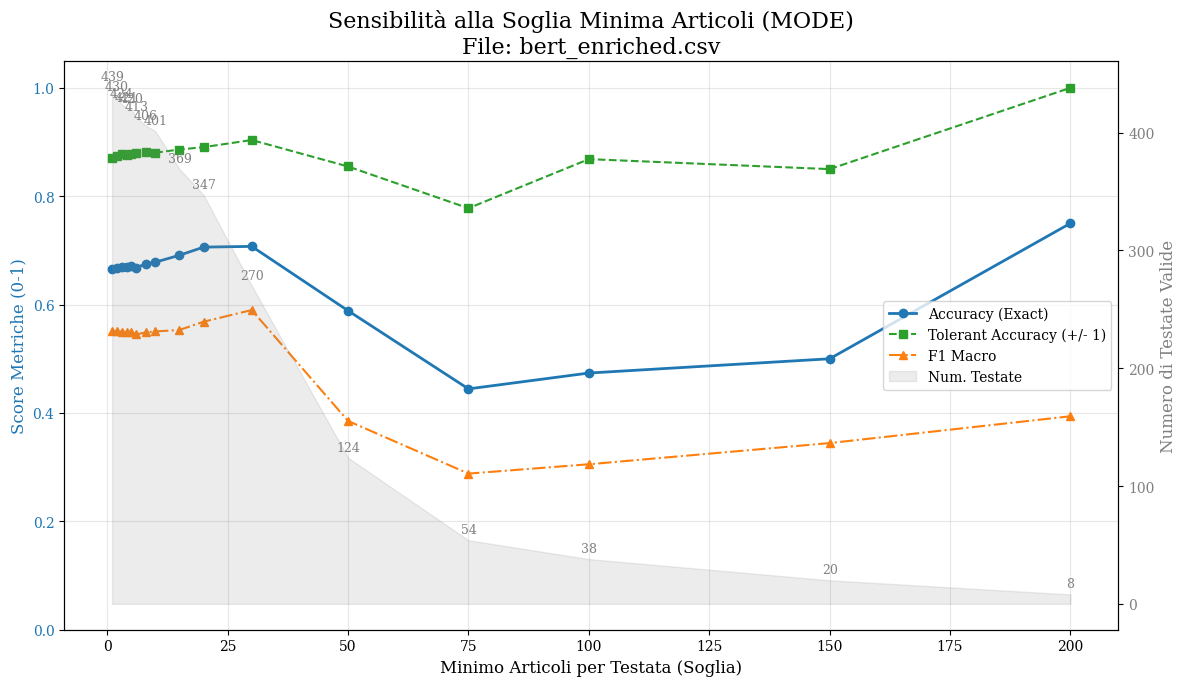

In [6]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# ==============================================================================
# 1. FUNZIONE HELPER PER ACCURATEZZA PESATA
# ==============================================================================
def calculate_weighted_accuracy(cm, adjacent_weight):
    """Calcola l'accuratezza permettendo errori adiacenti con un peso parziale."""
    n = cm.shape[0]
    total = np.sum(cm)
    if total == 0: return 0.0
    
    weights = np.zeros((n, n))
    for i in range(n):
        weights[i, i] = 1.0
        if i > 0: weights[i, i-1] = adjacent_weight
        if i < n-1: weights[i, i+1] = adjacent_weight

    return np.sum(cm * weights) / total

# ==============================================================================
# 2. FUNZIONE DI ANALISI SENSIBILITÀ (SOGLIA ARTICOLI)
# ==============================================================================

def analizza_sensibilita_soglia(csv_path, thresholds, aggregation_method='mode'):
    """
    Calcola come variano le metriche al variare del numero minimo di articoli richiesti per testata.
    Genera un grafico a doppio asse (Metriche vs Quantità Dati).

    Args:
        csv_path (str): Path del file CSV.
        thresholds (list): Lista di interi da testare come soglie (es. [1, 2, 3, 5, 10]).
        aggregation_method (str): 'mode' (maggioranza) o 'mean' (media arrotondata).
    """
    print(f"\n=== Analisi Sensibilità Soglia ({aggregation_method.upper()}) per: {csv_path} ===")
    
    # -------------------------------------------------------
    # A. Caricamento e Parsing (Fatto una volta sola per efficienza)
    # -------------------------------------------------------
    df_results = pd.read_csv(csv_path)
    all_predictions = []
    
    # Rilevamento automatico colonne
    cols = df_results.columns
    col_true = 'True_Labels' if 'True_Labels' in cols else 'Val_True_Labels'
    col_pred = 'Predicted_Labels' if 'Predicted_Labels' in cols else 'Val_Predictions'

    for idx, row in df_results.iterrows():
        try:
            domains = ast.literal_eval(row['Article_Domains'])
            true_labels = ast.literal_eval(row[col_true])
            pred_labels = ast.literal_eval(row[col_pred])
            
            for d, t, p in zip(domains, true_labels, pred_labels):
                all_predictions.append({'Domain': d, 'True_Label': t, 'Pred_Label': p})
        except Exception:
            continue

    if not all_predictions:
        print("Errore: Nessun dato caricato.")
        return

    # DataFrame "Flat" (un riga = un articolo)
    df_flat = pd.DataFrame(all_predictions)
    
    # Pre-calcoliamo il conteggio degli articoli per ogni dominio
    # Questo ci serve per filtrare velocemente dentro il loop
    domain_counts = df_flat['Domain'].value_counts()

    # Preparazione lista per salvare i risultati
    results_history = []

    # Definiamo la funzione di aggregazione
    if aggregation_method == 'mode':
        agg_func = lambda x: stats.mode(x, keepdims=True)[0][0]
    elif aggregation_method == 'mean':
        agg_func = lambda x: int(round(np.mean(x)))
    else:
        raise ValueError("Metodo non valido. Usa 'mode' o 'mean'.")

    # -------------------------------------------------------
    # B. Loop sulle Soglie (Thresholds)
    # -------------------------------------------------------
    for min_k in thresholds:
        
        # 1. Identifichiamo i domini validi per questa soglia
        valid_domains = domain_counts[domain_counts >= min_k].index
        
        # Se non ci sono abbastanza domini, saltiamo o interrompiamo
        if len(valid_domains) < 2: 
            print(f"  Soglia {min_k}: Troppi pochi domini ({len(valid_domains)}). Salto.")
            continue
            
        # 2. Filtriamo i dati
        df_subset = df_flat[df_flat['Domain'].isin(valid_domains)].copy()
        
        # 3. Aggregazione (Testata Level)
        df_agg = df_subset.groupby('Domain').agg({
            'True_Label': 'first',
            'Pred_Label': agg_func
        }).reset_index()
        
        # 4. Calcolo Metriche Chiave
        y_true = df_agg['True_Label']
        y_pred = df_agg['Pred_Label']
        all_labels = [0,1,2,3,4]
        cm = confusion_matrix(y_true, y_pred, labels=all_labels)
        
        acc = accuracy_score(y_true, y_pred)
        f1_macro = f1_score(y_true, y_pred, average='macro', zero_division=0)
        w_acc_1 = calculate_weighted_accuracy(cm, 1.0) # Accuracy +/- 1
        
        # Salviamo nel registro
        results_history.append({
            'Threshold': min_k,
            'Num_Domini': len(df_agg),
            'Accuracy': acc,
            'Tolerant_Acc_1.0': w_acc_1,
            'F1_Macro': f1_macro
        })
        
        print(f"  -> Min {min_k} Articoli: {len(df_agg)} Domini | Acc: {acc:.3f} | F1: {f1_macro:.3f}")

    # Creiamo un DataFrame dai risultati per facilitare il plotting
    df_res = pd.DataFrame(results_history)
    
    # -------------------------------------------------------
    # C. Visualizzazione (Doppio Asse Y)
    # -------------------------------------------------------
    if df_res.empty:
        return

    fig, ax1 = plt.subplots(figsize=(12, 7))
    plt.title(f"Sensibilità alla Soglia Minima Articoli ({aggregation_method.upper()})\nFile: {csv_path.split('/')[-1]}", fontsize=16)

    # ASSE X: Soglie
    x = df_res['Threshold'].astype(str) # Convertiamo in stringa per treating categorico equispaziato o numerico
    x_nums = df_res['Threshold']

    # --- ASSE Y SINISTRO (Metriche: Linee) ---
    ax1.set_xlabel('Minimo Articoli per Testata (Soglia)', fontsize=12)
    ax1.set_ylabel('Score Metriche (0-1)', fontsize=12, color='tab:blue')
    
    # Plot Linee con marcatori
    ax1.plot(x_nums, df_res['Accuracy'], marker='o', label='Accuracy (Exact)', color='tab:blue', linewidth=2)
    ax1.plot(x_nums, df_res['Tolerant_Acc_1.0'], marker='s', label='Tolerant Accuracy (+/- 1)', color='tab:green', linestyle='--')
    ax1.plot(x_nums, df_res['F1_Macro'], marker='^', label='F1 Macro', color='tab:orange', linestyle='-.')
    
    ax1.set_ylim(0, 1.05)
    ax1.tick_params(axis='y', labelcolor='tab:blue')
    ax1.grid(True, alpha=0.3)

    # --- ASSE Y DESTRO (Numero Domini: Area/Barre) ---
    ax2 = ax1.twinx()  # Crea un secondo asse che condivide la X
    ax2.set_ylabel('Numero di Testate Valide', fontsize=12, color='gray')
    
    # Usiamo un fill_between o barre per mostrare il volume dei dati
    ax2.fill_between(x_nums, 0, df_res['Num_Domini'], color='gray', alpha=0.15, label='Num. Testate')
    
    # Annotiamo il numero esatto di testate sopra i punti
    for i, txt in enumerate(df_res['Num_Domini']):
        ax2.annotate(txt, (x_nums.iloc[i], df_res['Num_Domini'].iloc[i]), 
                     textcoords="offset points", xytext=(0,5), ha='center', color='gray', fontsize=9)

    ax2.tick_params(axis='y', labelcolor='gray')

    # LEGENDA COMPLETA
    # Dobbiamo unire le legende dei due assi
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center right', bbox_to_anchor=(1, 0.5))

    plt.tight_layout()
    plt.show()
    
    return df_res

# ==============================================================================
# 3. ESECUZIONE
# ==============================================================================

SOGLIE_DA_TESTARE = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30, 50, 75, 100, 150, 200]

file_path = 'Results/Classification/bert_enriched.csv'

df_trend_mode = analizza_sensibilita_soglia(
    file_path, 
    thresholds=SOGLIE_DA_TESTARE, 
    aggregation_method='mode'
)




=== Randomized Analysis: bert_enriched (Seed=42, Agg=MODE) ===
----------------------------------------------------
Size  | Chunks | Acc    | Tol 1.0 | Tol 0.5 | F1 W. 
----------------------------------------------------
5     | 3730   | 0.6123 | 0.8517  | 0.7320  | 0.6064
10    | 1766   | 0.6166 | 0.8596  | 0.7381  | 0.6091
20    | 764    | 0.6060 | 0.8573  | 0.7317  | 0.5996
30    | 442    | 0.6154 | 0.8710  | 0.7432  | 0.6037
50    | 191    | 0.5550 | 0.8691  | 0.7120  | 0.5305
75    | 75     | 0.4533 | 0.8000  | 0.6267  | 0.4067
100   | 46     | 0.5000 | 0.8696  | 0.6848  | 0.4667

Graph saved to: Results/Plots/analysis_bert_enriched_mode.pdf


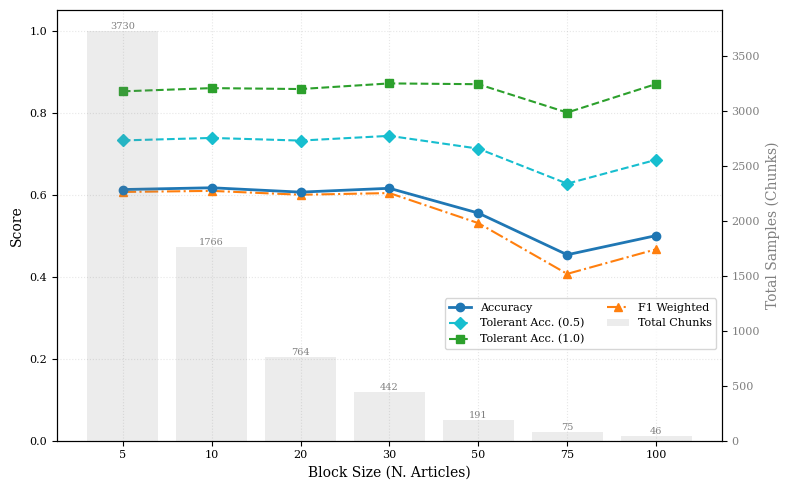

In [7]:
import pandas as pd
import numpy as np
import ast
import json
import os
import random
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

# ==============================================================================
# 1. GRAPHIC CONFIGURATION
# ==============================================================================
plt.rcParams.update({
    "text.usetex": False,            
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif", "serif"],
    "mathtext.fontset": "cm",        
    "axes.labelsize": 10,
    "font.size": 10,
    "legend.fontsize": 8,            
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "figure.figsize": (8, 5)         
})

OUTPUT_DIR = "Results/Plots"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ==============================================================================
# 2. HELPER FUNCTIONS
# ==============================================================================

def fast_parse_dense_cell(val_str, is_numeric=False):
    if not isinstance(val_str, str) or len(val_str) < 3: return []
    if is_numeric:
        try: return [int(x) for x in val_str[1:-1].split(',')]
        except: pass
    try:
        if val_str.startswith("['") and val_str.endswith("']"):
            return json.loads(val_str.replace("'", '"'))
    except: pass
    try: return ast.literal_eval(val_str)
    except: return []

def calculate_weighted_accuracy(cm, adjacent_weight):
    n = cm.shape[0]
    total = np.sum(cm)
    if total == 0: return 0.0
    
    weights = np.zeros((n, n))
    for i in range(n):
        weights[i, i] = 1.0
        if i > 0: weights[i, i-1] = adjacent_weight
        if i < n-1: weights[i, i+1] = adjacent_weight

    return np.sum(cm * weights) / total

# ==============================================================================
# 3. RANDOMIZED CHUNKING LOGIC
# ==============================================================================

def analyze_random_block_performance(csv_path, block_sizes, aggregation_method='mode', seed=42):
    # --- 1. Extract Model Name from Filename ---
    base_name = os.path.basename(csv_path)       # es. "bert_enriched.csv"
    model_name = os.path.splitext(base_name)[0]  # es. "bert_enriched"
    
    print(f"\n=== Randomized Analysis: {model_name} (Seed={seed}, Agg={aggregation_method.upper()}) ===")
    
    random.seed(seed)
    np.random.seed(seed)

    # --- 2. Load Data ---
    if not os.path.exists(csv_path):
        print(f"Error: File not found -> {csv_path}")
        return

    df_results = pd.read_csv(csv_path)
    all_articles = []
    
    cols = df_results.columns
    col_true = 'True_Labels' if 'True_Labels' in cols else 'Val_True_Labels'
    col_pred = 'Predicted_Labels' if 'Predicted_Labels' in cols else 'Val_Predictions'
    
    is_dense = len(df_results) < 50 and 'Fold' in cols

    for _, row in df_results.iterrows():
        try:
            if is_dense:
                domains = fast_parse_dense_cell(row['Article_Domains'], False)
                true_labels = fast_parse_dense_cell(row[col_true], True)
                pred_labels = fast_parse_dense_cell(row[col_pred], True)
            else:
                domains = ast.literal_eval(row['Article_Domains'])
                true_labels = ast.literal_eval(row[col_true])
                pred_labels = ast.literal_eval(row[col_pred])
            
            if domains and true_labels and pred_labels:
                min_len = min(len(domains), len(true_labels), len(pred_labels))
                for i in range(min_len):
                    all_articles.append({
                        'Domain': domains[i], 
                        'True_Label': true_labels[i], 
                        'Pred_Label': pred_labels[i]
                    })
        except Exception:
            continue

    if not all_articles:
        print("Error: No valid articles extracted.")
        return

    df_flat = pd.DataFrame(all_articles)
    
    domain_groups = {}
    for domain, group in df_flat.groupby('Domain'):
        true_lbl = group['True_Label'].iloc[0]
        preds = group['Pred_Label'].tolist()
        domain_groups[domain] = {'True': true_lbl, 'Preds': preds}

    results_history = []

    # --- 3. Loop over Sizes ---
    header = f"{'Size':<5} | {'Chunks':<6} | {'Acc':<6} | {'Tol 1.0':<7} | {'Tol 0.5':<7} | {'F1 W.':<6}"
    print("-" * len(header))
    print(header)
    print("-" * len(header))

    for size in block_sizes:
        chunk_true_labels = []
        chunk_pred_labels = []
        total_chunks = 0
        
        for domain, data in domain_groups.items():
            current_preds = data['Preds'][:] 
            random.shuffle(current_preds) 
            
            n_articles = len(current_preds)
            if n_articles < size: continue
            
            num_chunks = n_articles // size
            
            for i in range(num_chunks):
                start_idx = i * size
                end_idx = (i + 1) * size
                block_preds = current_preds[start_idx : end_idx]
                
                if aggregation_method == 'mode':
                    aggr_val = stats.mode(block_preds, keepdims=True)[0][0]
                elif aggregation_method == 'mean':
                    aggr_val = int(round(np.mean(block_preds)))
                
                chunk_pred_labels.append(aggr_val)
                chunk_true_labels.append(data['True'])
                total_chunks += 1
        
        if total_chunks == 0: continue

        # Metrics
        acc = accuracy_score(chunk_true_labels, chunk_pred_labels)
        f1_w = f1_score(chunk_true_labels, chunk_pred_labels, average='weighted', zero_division=0)
        
        cm = confusion_matrix(chunk_true_labels, chunk_pred_labels, labels=[0,1,2,3,4])
        w_acc_10 = calculate_weighted_accuracy(cm, 1.0)
        w_acc_05 = calculate_weighted_accuracy(cm, 0.5)
        
        results_history.append({
            'Block_Size': size,
            'Num_Chunks': total_chunks,
            'Accuracy': acc,
            'Tol_Acc_1.0': w_acc_10,
            'Tol_Acc_0.5': w_acc_05,
            'F1_Weighted': f1_w
        })
        
        print(f"{size:<5} | {total_chunks:<6} | {acc:.4f} | {w_acc_10:.4f}  | {w_acc_05:.4f}  | {f1_w:.4f}")

    # --- 4. Plotting ---
    if not results_history: return

    df_res = pd.DataFrame(results_history)
    
    fig, ax1 = plt.subplots(figsize=(8, 5))

    x_vals = df_res['Block_Size'].astype(str)
    
    # Lines
    ax1.plot(x_vals, df_res['Accuracy'], marker='o', label='Accuracy', color='tab:blue', linewidth=2, zorder=3)
    ax1.plot(x_vals, df_res['Tol_Acc_0.5'], marker='D', label='Tolerant Acc. (0.5)', color='tab:cyan', linestyle='--', linewidth=1.5)
    ax1.plot(x_vals, df_res['Tol_Acc_1.0'], marker='s', label='Tolerant Acc. (1.0)', color='tab:green', linestyle='--', linewidth=1.5)
    ax1.plot(x_vals, df_res['F1_Weighted'], marker='^', label='F1 Weighted', color='tab:orange', linestyle='-.', linewidth=1.5)
    
    ax1.set_xlabel('Block Size (N. Articles)', fontsize=10)
    ax1.set_ylabel('Score', fontsize=10, color='black')
    ax1.set_ylim(0, 1.05)
    ax1.grid(True, alpha=0.3, linestyle=':')
    
    # Bar Chart
    ax2 = ax1.twinx()
    ax2.bar(x_vals, df_res['Num_Chunks'], color='gray', alpha=0.15, label='Total Chunks')
    ax2.set_ylabel('Total Samples (Chunks)', fontsize=10, color='gray')
    ax2.tick_params(axis='y', labelcolor='gray')
    
    for i, v in enumerate(df_res['Num_Chunks']):
        ax2.text(i, v, str(v), ha='center', va='bottom', fontsize=7, color='gray')

    # Legend (Positioned Higher)
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    
    ax1.legend(
        lines1 + lines2, 
        labels1 + labels2, 
        loc='lower right', 
        bbox_to_anchor=(1.0, 0.2), # Legend raised to 20% height
        frameon=True, 
        ncol=2
    )

    plt.tight_layout()
    
    # --- 5. Dynamic Filename ---
    # Filename format: analysis_<MODEL_NAME>_<AGGREGATION>.pdf
    output_filename = f"analysis_{model_name}_{aggregation_method}.pdf"
    save_path = os.path.join(OUTPUT_DIR, output_filename)
    
    plt.savefig(save_path, bbox_inches='tight')
    print(f"\nGraph saved to: {save_path}")
    
    plt.show()

# ==============================================================================
# 4. EXECUTION
# ==============================================================================

BLOCK_SIZES = [5, 10, 20, 30, 50, 75, 100]

# Esempio: il file di output si chiamerà "analysis_bert_enriched_mode.pdf"
file_path = 'Results/Classification/bert_enriched.csv'

analyze_random_block_performance(
    file_path, 
    block_sizes=BLOCK_SIZES, 
    aggregation_method='mode', 
    seed=42 
)


=== Randomized Analysis: roberta_enriched (Seed=42, Agg=MODE) ===
----------------------------------------------------
Size  | Chunks | Acc    | Tol 1.0 | Tol 0.5 | F1 W. 
----------------------------------------------------
5     | 3730   | 0.6231 | 0.8461  | 0.7346  | 0.6161
10    | 1766   | 0.6195 | 0.8533  | 0.7364  | 0.6144
20    | 764    | 0.5982 | 0.8508  | 0.7245  | 0.5933
30    | 442    | 0.6131 | 0.8688  | 0.7410  | 0.6080
50    | 191    | 0.5288 | 0.8482  | 0.6885  | 0.5142
75    | 75     | 0.4400 | 0.8000  | 0.6200  | 0.4225
100   | 46     | 0.4348 | 0.8696  | 0.6522  | 0.4224

Graph saved to: Results/Plots/analysis_roberta_enriched_mode.pdf


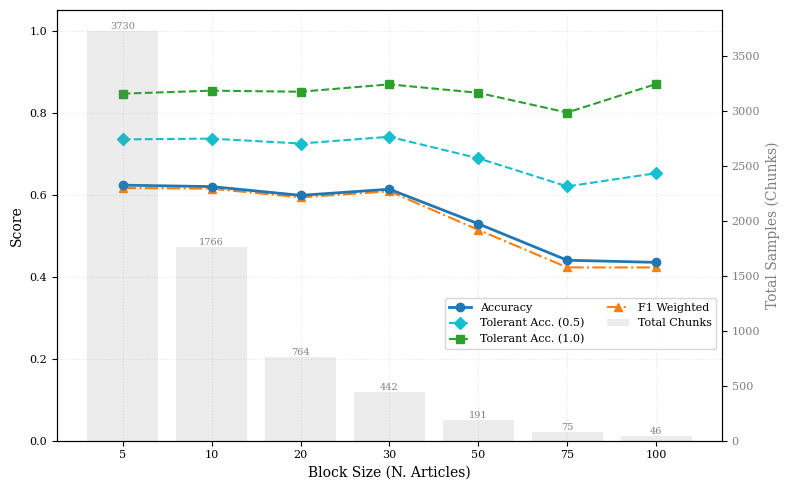

In [8]:
# Esempio: il file di output si chiamerà "analysis_bert_enriched_mode.pdf"
file_path = 'Results/Classification/roberta_enriched.csv'

analyze_random_block_performance(
    file_path, 
    block_sizes=BLOCK_SIZES, 
    aggregation_method='mode', 
    seed=42 
)


=== Randomized Analysis: llama_enriched (Seed=42, Agg=MODE) ===
----------------------------------------------------
Size  | Chunks | Acc    | Tol 1.0 | Tol 0.5 | F1 W. 
----------------------------------------------------
5     | 3730   | 0.6161 | 0.8622  | 0.7391  | 0.6222
10    | 1766   | 0.6212 | 0.8732  | 0.7472  | 0.6276
20    | 764    | 0.6047 | 0.8717  | 0.7382  | 0.6109
30    | 442    | 0.6041 | 0.8710  | 0.7376  | 0.6110
50    | 191    | 0.5393 | 0.8691  | 0.7042  | 0.5366
75    | 75     | 0.4400 | 0.8133  | 0.6267  | 0.3931
100   | 46     | 0.4565 | 0.8696  | 0.6630  | 0.4330

Graph saved to: Results/Plots/analysis_llama_enriched_mode.pdf


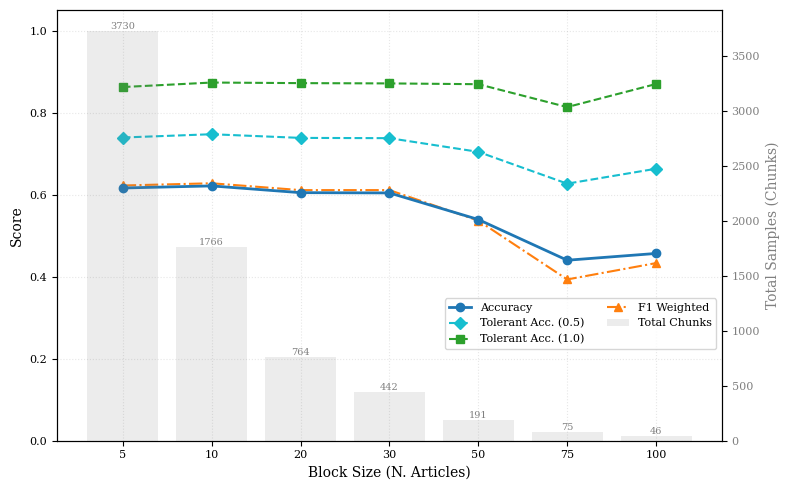

In [9]:
# Esempio: il file di output si chiamerà "analysis_bert_enriched_mode.pdf"
file_path = 'Results/Classification/llama_enriched.csv'

analyze_random_block_performance(
    file_path, 
    block_sizes=BLOCK_SIZES, 
    aggregation_method='mode', 
    seed=42 
)

# Nuova analisi post reject su IPM


### Import dati

In [10]:
import pandas as pd
bertDf = pd.read_csv('Results/Classification/bert_enriched.csv')


def normalize(df):
    # porta tutto allo standard Val_True_Labels / Val_Predictions / Article_IDs
    rename = {}
    if 'True_Labels' in df.columns: rename['True_Labels'] = 'Val_True_Labels'
    if 'Predicted_Labels' in df.columns: rename['Predicted_Labels'] = 'Val_Predictions'
    if 'Val_Article_IDs' in df.columns and 'Article_IDs' not in df.columns:
        rename['Val_Article_IDs'] = 'Article_IDs'
    return df.rename(columns=rename)

bertDf = normalize(bertDf)
bertDf

,Fold,Balanced_Accuracy,Accuracy,Precision_Micro,Precision_Macro,Precision_Weighted,Recall_Micro,Recall_Macro,Recall_Weighted,F1_Micro,F1_Macro,F1_Weighted,Confusion_Matrix,Val_True_Labels,Val_Predictions,Article_IDs,Article_URLs,Article_Domains
0,1,0.510007,0.570732,0.570732,0.519026,0.576988,0.570732,0.510007,0.570732,0.570732,0.510744,0.571108,"[[769, 37, 26, 68, 17], [30, 371, 275, 99, 21]...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[169, 170, 171, 172, 173, 174, 175, 176, 177, ...",['https://ecoklahomanews.com/stories/670532572...,"['ecoklahomanews.com', 'ecoklahomanews.com', '..."
1,2,0.487459,0.547319,0.547319,0.493514,0.560459,0.547319,0.487459,0.547319,0.547319,0.487836,0.551056,"[[727, 97, 69, 76, 18], [11, 299, 135, 123, 32...","[4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, ...","[3, 3, 0, 0, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, ...","[311, 312, 313, 314, 315, 316, 317, 318, 319, ...",['https://infacts.org/why-we-lost-and-where-we...,"['infacts.org', 'infacts.org', 'infacts.org', ..."
2,3,0.516695,0.604638,0.604638,0.534950,0.608693,0.604638,0.516695,0.604638,0.604638,0.515509,0.596506,"[[842, 5, 9, 15, 10], [14, 154, 84, 240, 46], ...","[4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, ...","[3, 3, 3, 3, 3, 3, 3, 0, 0, 3, 3, 3, 3, 3, 3, ...","[536, 537, 538, 539, 540, 541, 542, 543, 544, ...",['https://www.politico.eu/article/germanys-fri...,"['politico.eu', 'politico.eu', 'politico.eu', ..."
3,4,0.531071,0.576008,0.576008,0.548393,0.597615,0.576008,0.531071,0.576008,0.576008,0.535750,0.581898,"[[777, 127, 11, 132, 45], [56, 147, 13, 351, 4...","[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, ...","[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, ...","[98, 99, 100, 101, 102, 103, 104, 105, 106, 10...","['https://middlesboronews.com/category/news/',...","['middlesborodailynews.com', 'middlesborodaily..."
4,5,0.536891,0.616596,0.616596,0.542916,0.610219,0.616596,0.536891,0.616596,0.616596,0.537073,0.611042,"[[923, 7, 22, 35, 7], [82, 114, 42, 154, 82], ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...","[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,...",['https://nemontananews.com/stories/670532029-...,"['nemontananews.com', 'nemontananews.com', 'ne..."


## Stampo la distribuzione del nummero di articoli per dominio

### Le mediana è 34 quindi fino a quel numero ha senso

DISTRIBUZIONE GLOBALE
articoli totali: 19476
domini unici: 439

count    439.000000
mean      44.364465
std       41.372781
min        1.000000
25%       22.000000
50%       34.000000
75%       51.000000
max      294.000000
dtype: float64

DISTRIBUZIONE PER LABEL (y_true)

--- LABEL 0 ---
articoli totali label 0: 4871
domini che hanno questa label: 152 / 439
count    152.000000
mean      32.046053
std       17.324843
min        9.000000
25%       26.000000
50%       31.000000
75%       36.000000
max      197.000000
dtype: float64

--- LABEL 1 ---
articoli totali label 1: 3016
domini che hanno questa label: 69 / 439
count     69.000000
mean      43.710145
std       49.441023
min        1.000000
25%       12.000000
50%       31.000000
75%       51.000000
max      200.000000
dtype: float64

--- LABEL 2 ---
articoli totali label 2: 4620
domini che hanno questa label: 95 / 439
count     95.000000
mean      48.631579
std       31.003106
min        1.000000
25%       33.000000
50%       51.00

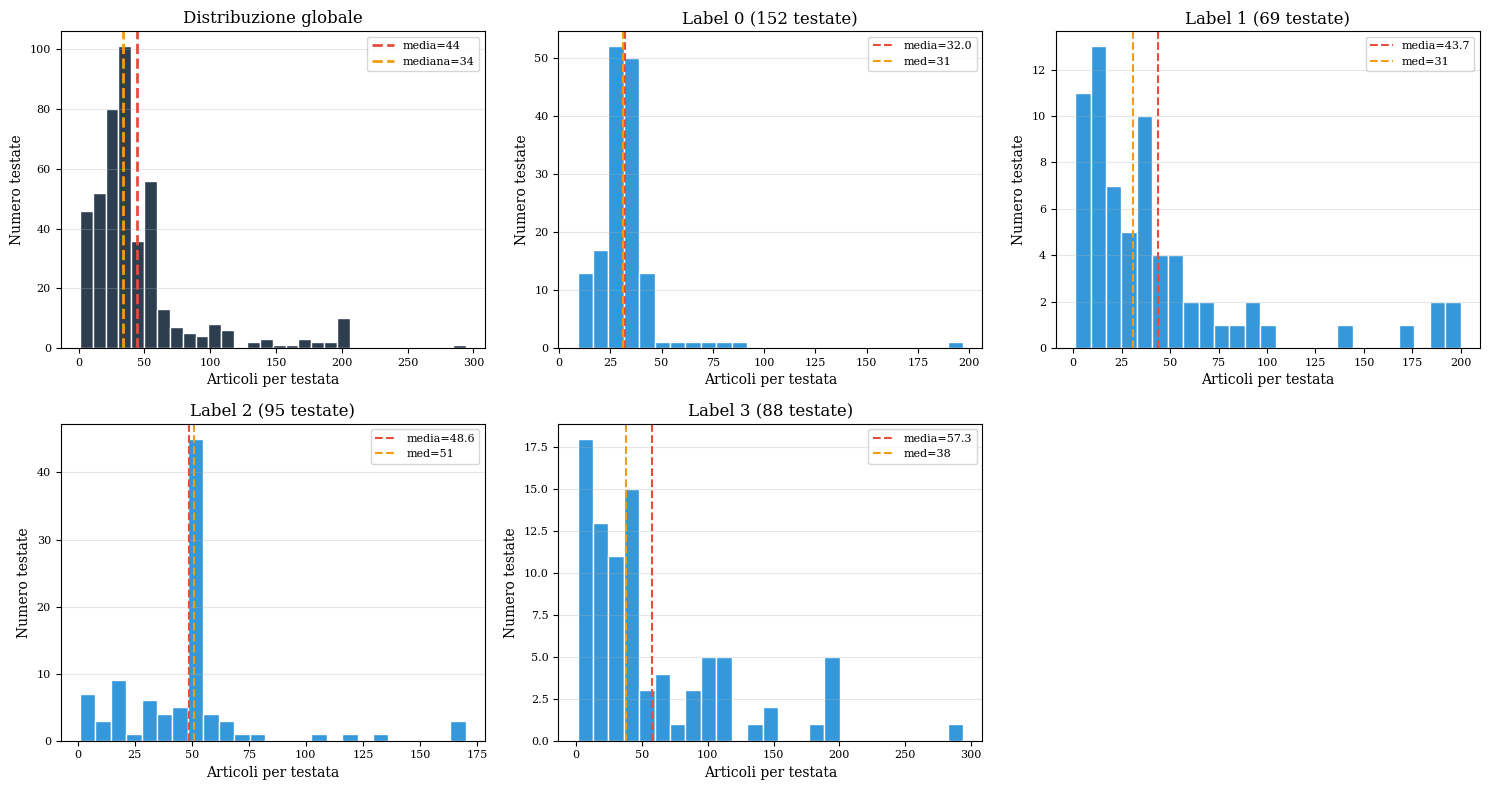

In [11]:
import pandas as pd
import ast
import matplotlib.pyplot as plt
import numpy as np

rows = []
for _, r in bertDf.iterrows():
    try:
        domains = ast.literal_eval(r['Article_Domains'])
        trues = ast.literal_eval(r['Val_True_Labels'])
        preds = ast.literal_eval(r['Val_Predictions'])
    except:
        continue
    for d, t, p in zip(domains, trues, preds):
        rows.append({'domain': d, 'y_true': int(t), 'y_pred': int(p)})

bert = pd.DataFrame(rows)

# 2. GLOBALI
print("="*60)
print("DISTRIBUZIONE GLOBALE")
print("="*60)
print("articoli totali:", len(bert))
print("domini unici:", bert['domain'].nunique())
print()
global_desc = bert.groupby('domain').size().describe()
print(global_desc)

# 3. PER SINGOLA LABEL
print()
print("="*60)
print("DISTRIBUZIONE PER LABEL (y_true)")
print("="*60)

label_stats = []
for label in sorted(bert['y_true'].unique()):
    per_dom = bert[bert['y_true'] == label].groupby('domain').size()

    print(f"\n--- LABEL {label} ---")
    print(f"articoli totali label {label}: {per_dom.sum()}")
    print(f"domini che hanno questa label: {len(per_dom)} / {bert['domain'].nunique()}")
    print(per_dom.describe())

    label_stats.append(per_dom.values)

# --- PLOT: 1 globale + 5 per label ---
counts_global = bert.groupby('domain').size().values
labels = sorted(bert['y_true'].unique())

fig, axes = plt.subplots(2, 3, figsize=(15,8))
axes = axes.flatten()

# 1) globale
ax = axes[0]
ax.hist(counts_global, bins=30, color='#2C3E50', edgecolor='white')
ax.axvline(counts_global.mean(), color='#E74C3C', ls='--', lw=2, label=f"media={counts_global.mean():.0f}")
ax.axvline(np.median(counts_global), color='#F39C12', ls='--', lw=2, label=f"mediana={np.median(counts_global):.0f}")
ax.set_title('Distribuzione globale')
ax.set_xlabel('Articoli per testata')
ax.set_ylabel('Numero testate')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# 2-6) per ogni label - SOLO TESTATE CON ALMENO 1 ARTICOLO
for i, label in enumerate(labels, start=1):
    ax = axes[i]
    per_dom = bert[bert['y_true'] == label].groupby('domain').size().values

    ax.hist(per_dom, bins=25, color='#3498DB', edgecolor='white')
    ax.axvline(per_dom.mean(), color='#E74C3C', ls='--', lw=1.5, label=f"media={per_dom.mean():.1f}")
    ax.axvline(np.median(per_dom), color='#F39C12', ls='--', lw=1.5, label=f"med={np.median(per_dom):.0f}")
    ax.set_title(f'Label {label} ({len(per_dom)} testate)')
    ax.set_xlabel('Articoli per testata')
    ax.set_ylabel('Numero testate')
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)

fig.delaxes(axes[5])
plt.tight_layout()
plt.savefig('distribuzione_per_label_corretta.png', dpi=300, bbox_inches='tight')
plt.show()

## Analizzo l'andamento delle performance

ANALISI BERT - CURVA ROBUSTA

Cosa stiamo misurando:
- k = numero di articoli usati per votare UN dominio

METODO:
- Prima: prendeva i PRIMI k articoli → bias da ordine
- Ora: 10 campioni casuali per ogni k → media robusta

DIFFERENZA TRA LE DUE METRICHE:
- acc_majority (STRETTA): conta giusto SOLO se predizione = verità
 es. vero=2, predici 2 → OK | predici 1 o 3 → SBAGLIATO

- acc_tolerant (LASSA): accetta errore di ±1 livello
 es. vero=2, predici 1,2,3 → OK | predici 0 o 4 → SBAGLIATO
 Serve perché la scala 0-4 è ordinale: sbagliare di 1 è quasi giusto

Perché è importante:
- a k=1 usiamo tutti gli articoli in media, non solo il primo
- a k=30 non buttiamo via articoli, li campioniamo
- oltre k=6-8 la curva si appiattisce → elbow
----------------------------------------------------------------------

 k  domini_usati  acc_majority  acc_tolerant
 1           430         0.630         0.833
 2           424         0.646         0.841
 3           421         0.650         0.846
 4   

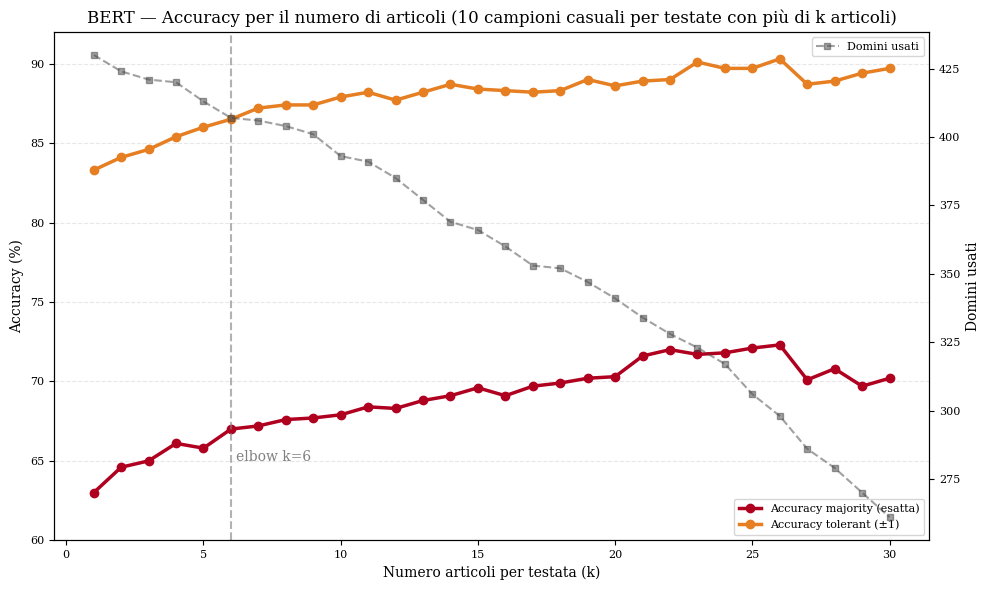

In [12]:
import pandas as pd, ast, numpy as np
from collections import Counter
import matplotlib.pyplot as plt

# --- SPIEGAZIONE COMPLETA NELL'OUTPUT ---
print("="*70)
print("ANALISI BERT - CURVA ROBUSTA")
print("="*70)
print()
print("Cosa stiamo misurando:")
print("- k = numero di articoli usati per votare UN dominio")
print()
print("METODO:")
print("- Prima: prendeva i PRIMI k articoli → bias da ordine")
print("- Ora: 10 campioni casuali per ogni k → media robusta")
print()
print("DIFFERENZA TRA LE DUE METRICHE:")
print("- acc_majority (STRETTA): conta giusto SOLO se predizione = verità")
print(" es. vero=2, predici 2 → OK | predici 1 o 3 → SBAGLIATO")
print()
print("- acc_tolerant (LASSA): accetta errore di ±1 livello")
print(" es. vero=2, predici 1,2,3 → OK | predici 0 o 4 → SBAGLIATO")
print(" Serve perché la scala 0-4 è ordinale: sbagliare di 1 è quasi giusto")
print()
print("Perché è importante:")
print("- a k=1 usiamo tutti gli articoli in media, non solo il primo")
print("- a k=30 non buttiamo via articoli, li campioniamo")
print("- oltre k=6-8 la curva si appiattisce → elbow")
print("-"*70)
print()

# --- CALCOLO ---
def majority(v): return Counter(v).most_common(1)[0][0]

np.random.seed(42)
risultati = []

for k in range(1, 31):
    acc_m = acc_t = domini = 0
    for dom, g in bert.groupby('domain'):
        if len(g) < k: continue
        true = g['y_true'].mode()[0]
        preds = g['y_pred'].values
        hits_m = hits_t = 0
        if len(g) == k:
            p = majority(preds)
            hits_m = int(p == true)
            hits_t = int(abs(p - true) <= 1)
        else:  # len(g) > k
            for _ in range(10):
                idx = np.random.choice(len(preds), k, replace=False)
                p = majority(preds[idx])
                hits_m += (p == true)
                hits_t += (abs(p-true) <= 1)

            acc_m += hits_m/10
            acc_t += hits_t/10
            domini += 1

    risultati.append([k, domini, round(acc_m/domini,3), round(acc_t/domini,3)])

df = pd.DataFrame(risultati, columns=['k','domini_usati','acc_majority','acc_tolerant'])
print(df.to_string(index=False))
print()
print("LETTURA RAPIDA:")
print(f"- A k=1: majority={df.loc[0,'acc_majority']}, tolerant={df.loc[0,'acc_tolerant']}")
print(f"- A k=6: majority={df.loc[5,'acc_majority']}, tolerant={df.loc[5,'acc_tolerant']}")
print(f"- Guadagno tolerant: +{round((df.loc[5,'acc_tolerant']-df.loc[5,'acc_majority'])*100,1)} punti")

# --- PLOT ---
fig, ax1 = plt.subplots(figsize=(10,6))

# accuracy
ax1.plot(df['k'], df['acc_majority']*100, 'o-', lw=2.5, ms=6, color='#B00020', label='Accuracy majority (esatta)')
ax1.plot(df['k'], df['acc_tolerant']*100, 'o-', lw=2.5, ms=6, color='#E67E22', label='Accuracy tolerant (±1)')
ax1.axvline(6, color='gray', ls='--', alpha=0.6)
ax1.text(6.2, 65, 'elbow k=6', color='gray', fontsize=10)
ax1.set_xlabel('Numero articoli per testata (k)')
ax1.set_ylabel('Accuracy (%)')
ax1.set_ylim(60, 92)
ax1.grid(axis='y', ls='--', alpha=0.3)
ax1.legend(loc='lower right')

# domini usati (asse destro)
ax2 = ax1.twinx()
ax2.plot(df['k'], df['domini_usati'], 's--', color='#444', alpha=0.5, ms=4, label='Domini usati')
ax2.set_ylabel('Domini usati')
ax2.legend(loc='upper right')

plt.title('BERT — Accuracy per il numero di articoli (10 campioni casuali per testate con più di k articoli)', fontsize=12)
plt.tight_layout()
plt.show()

In [13]:
import pandas as pd, ast, numpy as np
from collections import Counter

# PASSO 0 - carica

rows = []
for _, r in bertDf.iterrows():
    domains = ast.literal_eval(r['Article_Domains'])
    trues = ast.literal_eval(r['Val_True_Labels'])
    preds = ast.literal_eval(r['Val_Predictions'])
    for d,t,p in zip(domains, trues, preds):
        rows.append({'domain':d, 'y_true':int(t), 'y_pred':int(p)})
bert = pd.DataFrame(rows)

print("PASSO 1 - DATI")
print(f"Hai {len(bert)} articoli, {bert['domain'].nunique()} domini")
print()

# PASSO 2
stats = []
for dom, g in bert.groupby('domain'):
    true = g['y_true'].iloc[0]
    preds = g['y_pred'].values
    stats.append({
        'domain': dom, 'true': true, 'n': len(preds),
        'var': np.var(preds), 'acc_1': (preds == true).mean(),
        'majority': Counter(preds).most_common(1)[0][0]
    })
df = pd.DataFrame(stats)
df['majority_ok'] = (df['majority'] == df['true'])
df['tolerant_ok'] = (abs(df['majority'] - df['true']) <= 1)

print("PASSO 2 - VARIANZA")
print(f"Varianza media: {df['var'].mean():.2f}")
print("var = media((pred - media_pred)^2) | 0=stabile, >1=salta tra livelli")
print()

# PASSO 3 - con soglie esplicite
stabili = df[df['var'] < 0.25]
medi = df[(df['var'] >= 0.25) & (df['var'] < 1.0)]
instabili = df[df['var'] >= 1.0]

print("PASSO 3 - TRE GRUPPI")
print(f"STABILI (var < 0.25): {len(stabili)} ({len(stabili)/len(df):.0%})")
print(f"MEDI (0.25 ≤ var < 1.0): {len(medi)} ({len(medi)/len(df):.0%})")
print(f"INSTABILI (var ≥ 1.0): {len(instabili)} ({len(instabili)/len(df):.0%})")
print()

# PASSO 4 - con tolerant
print("PASSO 4 - L'AGGREGAZIONE AIUTA?")
for nome, gruppo in [('STABILI', stabili), ('MEDI', medi), ('INSTABILI', instabili)]:
    k1 = gruppo['acc_1'].mean()
    maj = gruppo['majority_ok'].mean()
    tol = gruppo['tolerant_ok'].mean()
    print(f"{nome:9s}: k=1 {k1:.1%} | majority {maj:.1%} ({maj-k1:+.1%}) | tolerant {tol:.1%} (+{tol-maj:.1%})")
print()

# PASSO 5 - 3 profili medi senza esempi
print("PASSO 5 - TRE PROFILI TIPICI")
for nome, gruppo in [('BASSA VARIANZA', stabili), ('MEDIA VARIANZA', medi), ('ALTA VARIANZA', instabili)]:
    print()
    print(f"{nome}:")
    print(f" var media = {gruppo['var'].mean():.2f}")
    print(f" acc k=1 = {gruppo['acc_1'].mean():.1%}")
    print(f" majority = {gruppo['majority_ok'].mean():.1%}")
    print(f" tolerant = {gruppo['tolerant_ok'].mean():.1%}")
    if nome == 'BASSA VARIANZA':
        print(" → BERT predice quasi sempre uguale, 1 articolo basta")
    elif nome == 'MEDIA VARIANZA':
        print(" → BERT esita tra 2 livelli vicini, la tolerant recupera quasi tutto")
    else:
        print(" → BERT è incerto, anche la maggioranza sbaglia spesso ma di 1 livello")
print()

# PASSO 6
print("PASSO 6 - TOTALE")
print(f"majority: {df['majority_ok'].mean():.1%} | tolerant: {df['tolerant_ok'].mean():.1%}")

PASSO 1 - DATI
Hai 19476 articoli, 439 domini

PASSO 2 - VARIANZA
Varianza media: 0.51
var = media((pred - media_pred)^2) | 0=stabile, >1=salta tra livelli

PASSO 3 - TRE GRUPPI
STABILI (var < 0.25): 219 (50%)
MEDI (0.25 ≤ var < 1.0): 126 (29%)
INSTABILI (var ≥ 1.0): 94 (21%)

PASSO 4 - L'AGGREGAZIONE AIUTA?
STABILI  : k=1 89.8% | majority 90.4% (+0.7%) | tolerant 96.3% (+5.9%)
MEDI     : k=1 42.9% | majority 50.8% (+7.9%) | tolerant 84.1% (+33.3%)
INSTABILI: k=1 28.9% | majority 30.9% (+1.9%) | tolerant 66.0% (+35.1%)

PASSO 5 - TRE PROFILI TIPICI

BASSA VARIANZA:
 var media = 0.03
 acc k=1 = 89.8%
 majority = 90.4%
 tolerant = 96.3%
 → BERT predice quasi sempre uguale, 1 articolo basta

MEDIA VARIANZA:
 var media = 0.66
 acc k=1 = 42.9%
 majority = 50.8%
 tolerant = 84.1%
 → BERT esita tra 2 livelli vicini, la tolerant recupera quasi tutto

ALTA VARIANZA:
 var media = 1.44
 acc k=1 = 28.9%
 majority = 30.9%
 tolerant = 66.0%
 → BERT è incerto, anche la maggioranza sbaglia spesso ma d

In [14]:
df

,domain,true,n,var,acc_1,majority,majority_ok,tolerant_ok
0,5pillarsuk.com,3,17,0.297578,0.823529,3,True,True
1,aapsonline.org,0,9,0.691358,0.000000,1,False,True
2,aclu.org,3,89,0.999874,0.370787,1,False,False
3,aei.org,3,145,2.171986,0.268966,3,True,True
4,africanvoiceonline.co.uk,2,22,1.026860,0.090909,3,False,True
...,...,...,...,...,...,...,...,...
434,weststarknews.com,0,14,0.000000,1.000000,0,True,True
435,westvolusianews.com,0,12,0.000000,1.000000,0,True,True
436,williamsonnews.com,0,25,0.345600,0.960000,0,True,True
437,winchestersun.com,2,55,0.000000,1.000000,2,True,True


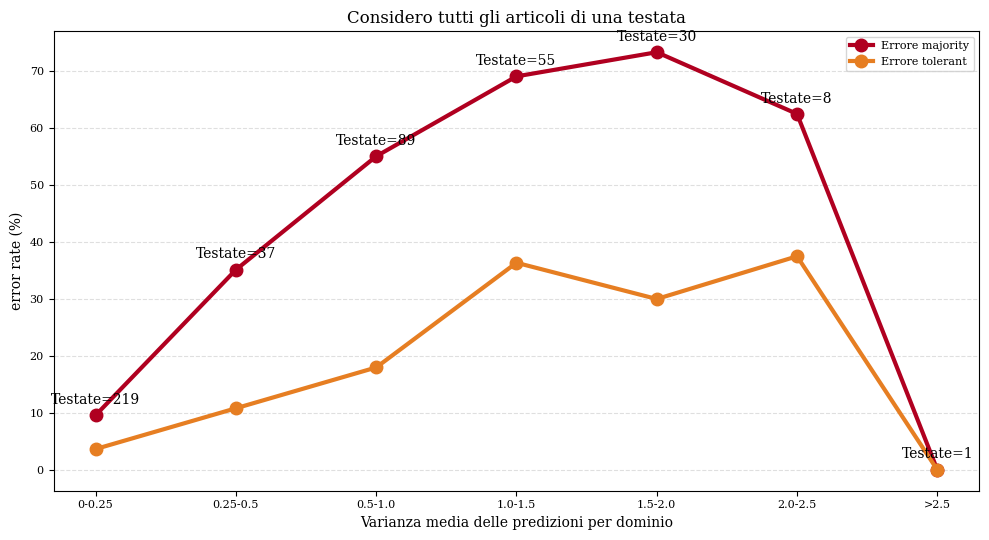

     bin   n  var_mean   err_maj   err_tol
  0-0.25 219  0.027504  9.589041  3.652968
0.25-0.5  37  0.381300 35.135135 10.810811
 0.5-1.0  89  0.778647 55.056180 17.977528
 1.0-1.5  55  1.197324 69.090909 36.363636
 1.5-2.0  30  1.646521 73.333333 30.000000
 2.0-2.5   8  2.156821 62.500000 37.500000
    >2.5   1  2.809600  0.000000  0.000000

Totale testate contate: 439


In [15]:
import matplotlib.pyplot as plt
import pandas as pd

bins = [0, 0.25, 0.5, 1.0, 1.5, 2.0, 2.5, df['var'].max()+0.01]
labels = ['0-0.25','0.25-0.5','0.5-1.0','1.0-1.5','1.5-2.0','2.0-2.5','>2.5']

# FIX QUI
df['bin'] = pd.cut(df['var'], bins=bins, labels=labels, right=False)

g = df.groupby('bin', observed=True).agg(
    err_maj=('majority_ok', lambda x: (1-x.mean())*100),
    err_tol=('tolerant_ok', lambda x: (1-x.mean())*100),
    n=('domain','count'),
    var_mean=('var','mean')
).reset_index()

plt.figure(figsize=(10,5.5))
plt.plot(g['bin'], g['err_maj'], 'o-', lw=3, ms=9, color='#B00020', label='Errore majority')
plt.plot(g['bin'], g['err_tol'], 'o-', lw=3, ms=9, color='#E67E22', label='Errore tolerant')

for i, row in g.iterrows():
    plt.text(i, row['err_maj']+2, f"Testate={int(row['n'])}", ha='center', fontsize=10)

plt.ylabel('error rate (%)')
plt.xlabel('Varianza media delle predizioni per dominio')
plt.grid(axis='y', ls='--', alpha=0.4)
plt.legend()
plt.title('Considero tutti gli articoli di una testata')
plt.tight_layout()
plt.show()

print(g[['bin','n','var_mean','err_maj','err_tol']].to_string(index=False))
print("\nTotale testate contate:", g['n'].sum())

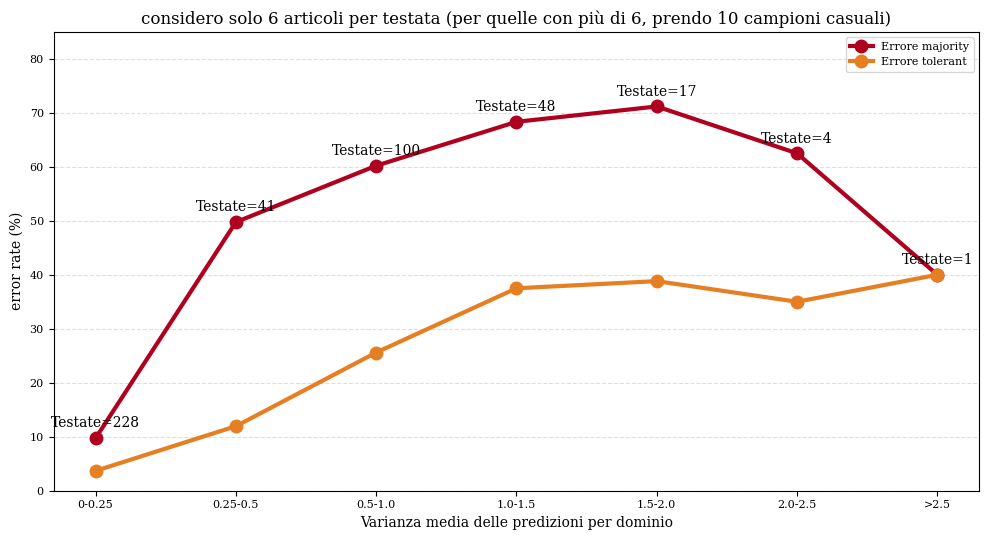

     bin   n  var_mean   err_maj   err_tol
  0-0.25 228  0.027875  9.736842  3.684211
0.25-0.5  41  0.368360 49.756098 11.951220
 0.5-1.0 100  0.768583 60.200000 25.600000
 1.0-1.5  48  1.225573 68.333333 37.500000
 1.5-2.0  17  1.685131 71.176471 38.823529
 2.0-2.5   4  2.192083 62.500000 35.000000
    >2.5   1  2.897222 40.000000 40.000000


In [16]:
import pandas as pd
import numpy as np
from collections import Counter

k = 6
rows = []

for dom, g in bert.groupby('domain'):
    preds_all = g['y_pred'].values
    true = g['y_true'].mode()[0]
    n = len(preds_all)

    # se hai meno di k articoli, usa quello che hai (1 sola volta)
    # se ne hai di più, fai 10 campioni come facevi per l'accuracy
    n_rep = 10 if n > k else 1

    vars_k = []
    maj_oks = []
    tol_oks = []

    for _ in range(n_rep):
        sample = np.random.choice(preds_all, min(k, n), replace=False)
        var_k = np.var(sample)
        maj = Counter(sample).most_common(1)[0][0]

        vars_k.append(var_k)
        maj_oks.append(maj == true)
        tol_oks.append(abs(maj - true) <= 1)

    # media dei 10 campioni = stima stabile per quel dominio a k=6
    rows.append({
        'domain': dom,
        'var': np.mean(vars_k),
        'majority_ok': np.mean(maj_oks),
        'tolerant_ok': np.mean(tol_oks),
        'n_articoli': n
    })

df = pd.DataFrame(rows)

# con k=6 la var max è ~2, mettiamo un tetto fisso a 10 per sicurezza
bins = [0, 0.25, 0.5, 1.0, 1.5, 2.0, 2.5, 10]
labels = ['0-0.25','0.25-0.5','0.5-1.0','1.0-1.5','1.5-2.0','2.0-2.5','>2.5']
df['bin'] = pd.cut(df['var'], bins=bins, labels=labels, right=False)
g = df.groupby('bin', observed=True).agg(
    err_maj=('majority_ok', lambda x: (1-x.mean())*100),
    err_tol=('tolerant_ok', lambda x: (1-x.mean())*100),
    n=('domain','count'),
    var_mean=('var','mean')
).reset_index()

import matplotlib.pyplot as plt
plt.figure(figsize=(10,5.5))
plt.plot(g['bin'], g['err_maj'], 'o-', lw=3, ms=9, color='#B00020', label='Errore majority')
plt.plot(g['bin'], g['err_tol'], 'o-', lw=3, ms=9, color='#E67E22', label='Errore tolerant')

for i, row in g.iterrows():
    if pd.notna(row['n']):
        plt.text(i, row['err_maj']+2, f"Testate={int(row['n'])}", ha='center', fontsize=10)

plt.ylabel('error rate (%)')
plt.xlabel('Varianza media delle predizioni per dominio')
plt.ylim(0,85)
plt.grid(axis='y', ls='--', alpha=0.4)
plt.legend()
plt.title('considero solo 6 articoli per testata (per quelle con più di 6, prendo 10 campioni casuali)')
plt.tight_layout()
plt.show()

print(g[['bin','n','var_mean','err_maj','err_tol']].to_string(index=False))

## Risposta a Manuel

Per la prima parte, come proposi già l'altra volta (secondo me eh) per avere un confronto valido si dovrebbe considerare sempre le stesse testate (i.e., per k che va da 1 a 30 o quello che è utilizzarei sempre i soliti 270 domini che hai per k=30).

ANALISI BERT - CURVA ROBUSTA (DOMINI FISSI)

Cosa cambia:
- Usiamo SEMPRE gli stessi domini per ogni k
- Selezionati: domini con ≥30 articoli (n=270)
- Così confrontiamo mele con mele
----------------------------------------------------------------------

Domini fissi usati per tutti i k: 270

 k  domini_usati  acc_majority  acc_tolerant
 1           270         0.673         0.856
 2           270         0.666         0.861
 3           270         0.684         0.865
 4           270         0.687         0.874
 5           270         0.689         0.885
 6           270         0.693         0.878
 7           270         0.702         0.887
 8           270         0.697         0.880
 9           270         0.696         0.891
10           270         0.704         0.889
11           270         0.706         0.893
12           270         0.700         0.889
13           270         0.701         0.888
14           270         0.699         0.887
15           270         0.708

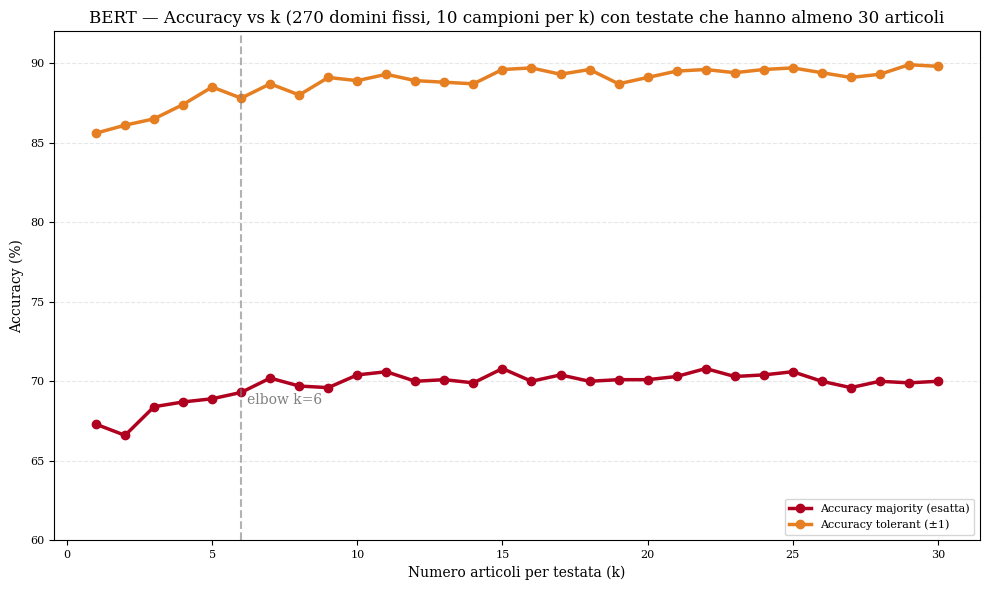

In [17]:
import pandas as pd, ast, numpy as np
from collections import Counter
import matplotlib.pyplot as plt

# --- SPIEGAZIONE ---
print("="*70)
print("ANALISI BERT - CURVA ROBUSTA (DOMINI FISSI)")
print("="*70)
print()
print("Cosa cambia:")
print("- Usiamo SEMPRE gli stessi domini per ogni k")
print("- Selezionati: domini con ≥30 articoli (n=270)")
print("- Così confrontiamo mele con mele")
print("-"*70)
print()

# --- FILTRO DOMINI FISSI ---
domini_fissi = bert.groupby('domain').filter(lambda g: len(g) >= 30)['domain'].unique()
bert_fisso = bert[bert['domain'].isin(domini_fissi)].copy()
print(f"Domini fissi usati per tutti i k: {len(domini_fissi)}")
print()

# --- CALCOLO ---
def majority(v): return Counter(v).most_common(1)[0][0]

np.random.seed(42)
risultati = []

for k in range(1, 31):
    acc_m = acc_t = 0
    for dom, g in bert_fisso.groupby('domain'):
        true = g['y_true'].mode()[0]
        preds = g['y_pred'].values

        hits_m = hits_t = 0
        for _ in range(10):
            idx = np.random.choice(len(preds), k, replace=False)
            p = majority(preds[idx])
            hits_m += (p == true)
            hits_t += (abs(p-true) <= 1)

        acc_m += hits_m/10
        acc_t += hits_t/10

    domini = len(domini_fissi)
    risultati.append([k, domini, round(acc_m/domini,3), round(acc_t/domini,3)])

df = pd.DataFrame(risultati, columns=['k','domini_usati','acc_majority','acc_tolerant'])
print(df.to_string(index=False))
print()
print("LETTURA RAPIDA:")
print(f"- A k=1: majority={df.loc[0,'acc_majority']}, tolerant={df.loc[0,'acc_tolerant']}")
print(f"- A k=6: majority={df.loc[5,'acc_majority']}, tolerant={df.loc[5,'acc_tolerant']}")
print(f"- Guadagno da 6 a 30: +{round((df.loc[29,'acc_majority']-df.loc[5,'acc_majority'])*100,1)} punti majority")

# --- PLOT ---
fig, ax1 = plt.subplots(figsize=(10,6))

ax1.plot(df['k'], df['acc_majority']*100, 'o-', lw=2.5, ms=6, color='#B00020', label='Accuracy majority (esatta)')
ax1.plot(df['k'], df['acc_tolerant']*100, 'o-', lw=2.5, ms=6, color='#E67E22', label='Accuracy tolerant (±1)')
ax1.axvline(6, color='gray', ls='--', alpha=0.6)
ax1.text(6.2, df['acc_majority'].min()*100+2, 'elbow k=6', color='gray', fontsize=10)
ax1.set_xlabel('Numero articoli per testata (k)')
ax1.set_ylabel('Accuracy (%)')
ax1.set_ylim(60, 92)
ax1.grid(axis='y', ls='--', alpha=0.3)
ax1.legend(loc='lower right')

plt.title(f'BERT — Accuracy vs k (270 domini fissi, 10 campioni per k) con testate che hanno almeno 30 articoli')
plt.tight_layout()
plt.savefig('curva_k_domini_fissi.png', dpi=300)
plt.show()

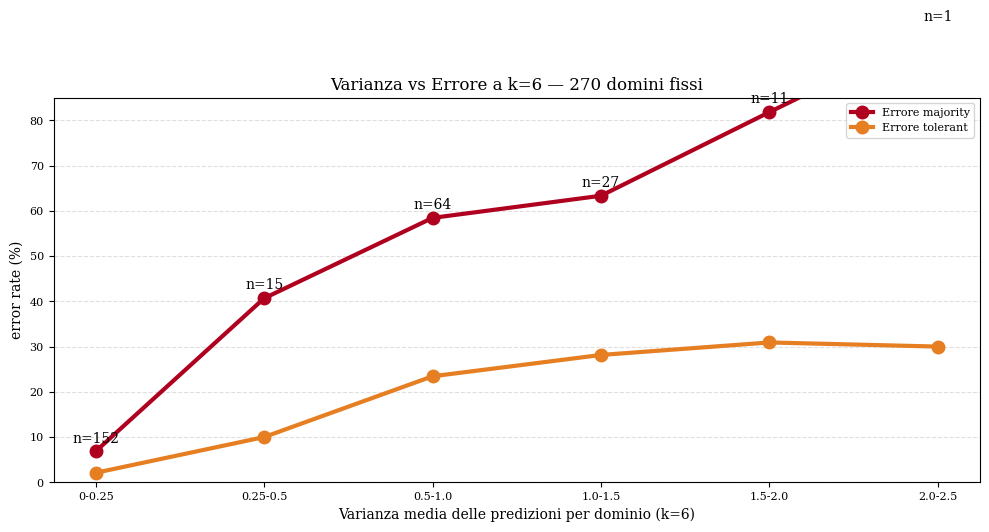

     bin   n  var_mean    err_maj   err_tol
  0-0.25 152  0.030428   6.842105  2.105263
0.25-0.5  15  0.400370  40.666667 10.000000
 0.5-1.0  64  0.752040  58.437500 23.437500
 1.0-1.5  27  1.215123  63.333333 28.148148
 1.5-2.0  11  1.663384  81.818182 30.909091
 2.0-2.5   1  2.086111 100.000000 30.000000

Domini analizzati: 270 (tutti con ≥30 articoli)


In [18]:
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

k = 6

# --- USA STESSI DOMINI FISSI ---
domini_fissi = bert.groupby('domain').filter(lambda g: len(g) >= 30)['domain'].unique()
bert_fisso = bert[bert['domain'].isin(domini_fissi)].copy()

rows = []
np.random.seed(42)

for dom, g in bert_fisso.groupby('domain'):
    preds_all = g['y_pred'].values
    true = g['y_true'].mode()[0]

    vars_k = []
    maj_oks = []
    tol_oks = []

    for _ in range(10):
        sample = np.random.choice(preds_all, k, replace=False)
        var_k = np.var(sample)
        maj = Counter(sample).most_common(1)[0][0]

        vars_k.append(var_k)
        maj_oks.append(maj == true)
        tol_oks.append(abs(maj - true) <= 1)

    rows.append({
        'domain': dom,
        'var': np.mean(vars_k),
        'majority_ok': np.mean(maj_oks),
        'tolerant_ok': np.mean(tol_oks),
        'n_articoli': len(preds_all)
    })

df = pd.DataFrame(rows)

bins = [0, 0.25, 0.5, 1.0, 1.5, 2.0, 2.5, 10]
labels = ['0-0.25','0.25-0.5','0.5-1.0','1.0-1.5','1.5-2.0','2.0-2.5','>2.5']
df['bin'] = pd.cut(df['var'], bins=bins, labels=labels, right=False)

g = df.groupby('bin', observed=True).agg(
    err_maj=('majority_ok', lambda x: (1-x.mean())*100),
    err_tol=('tolerant_ok', lambda x: (1-x.mean())*100),
    n=('domain','count'),
    var_mean=('var','mean')
).reset_index()

plt.figure(figsize=(10,5.5))
plt.plot(g['bin'], g['err_maj'], 'o-', lw=3, ms=9, color='#B00020', label='Errore majority')
plt.plot(g['bin'], g['err_tol'], 'o-', lw=3, ms=9, color='#E67E22', label='Errore tolerant')

for i, row in g.iterrows():
    if pd.notna(row['n']):
        plt.text(i, row['err_maj']+2, f"n={int(row['n'])}", ha='center', fontsize=10)

plt.ylabel('error rate (%)')
plt.xlabel('Varianza media delle predizioni per dominio (k=6)')
plt.ylim(0,85)
plt.grid(axis='y', ls='--', alpha=0.4)
plt.legend()
plt.title(f'Varianza vs Errore a k=6 — 270 domini fissi')
plt.tight_layout()
plt.savefig('varianza_errore_domini_fissi.png', dpi=300)
plt.show()

print(g[['bin','n','var_mean','err_maj','err_tol']].to_string(index=False))
print(f"\nDomini analizzati: {len(df)} (tutti con ≥30 articoli)")

Domini fissi: 270


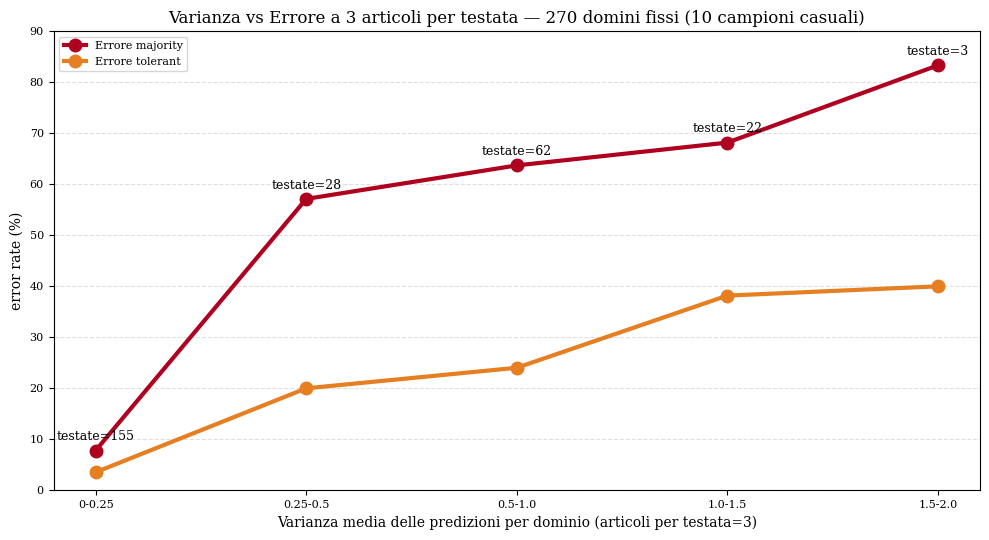

RISULTATI PER k=3
     bin   n  var_mean   err_maj   err_tol
  0-0.25 155  0.026667  7.806452  3.548387
0.25-0.5  28  0.361905 57.142857 20.000000
 0.5-1.0  62  0.713262 63.709677 24.032258
 1.0-1.5  22  1.201010 68.181818 38.181818
 1.5-2.0   3  1.629630 83.333333 40.000000



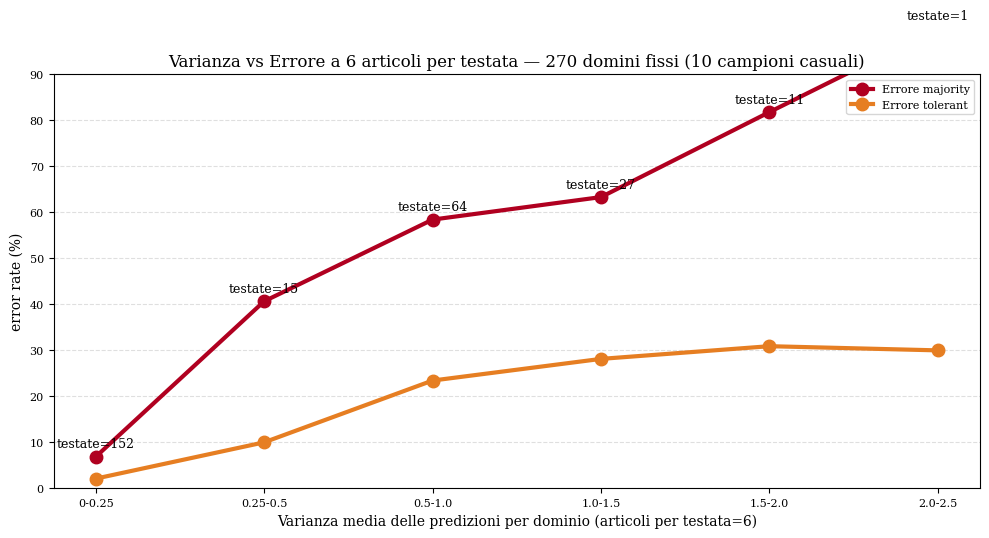

RISULTATI PER k=6
     bin   n  var_mean    err_maj   err_tol
  0-0.25 152  0.030428   6.842105  2.105263
0.25-0.5  15  0.400370  40.666667 10.000000
 0.5-1.0  64  0.752040  58.437500 23.437500
 1.0-1.5  27  1.215123  63.333333 28.148148
 1.5-2.0  11  1.663384  81.818182 30.909091
 2.0-2.5   1  2.086111 100.000000 30.000000



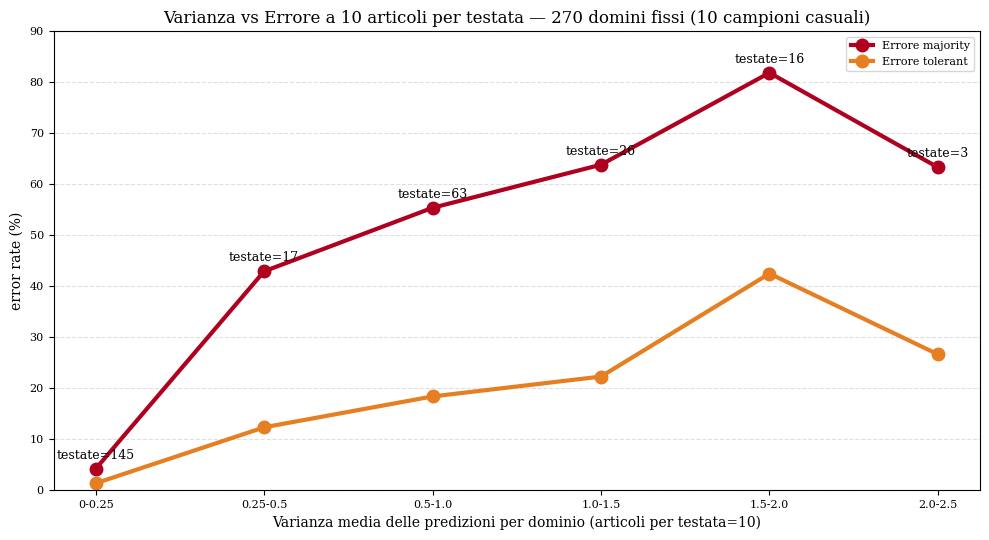

RISULTATI PER k=10
     bin   n  var_mean   err_maj   err_tol
  0-0.25 145  0.027434  4.206897  1.379310
0.25-0.5  17  0.366471 42.941176 12.352941
 0.5-1.0  63  0.754444 55.396825 18.412698
 1.0-1.5  26  1.187154 63.846154 22.307692
 1.5-2.0  16  1.647125 81.875000 42.500000
 2.0-2.5   3  2.088667 63.333333 26.666667



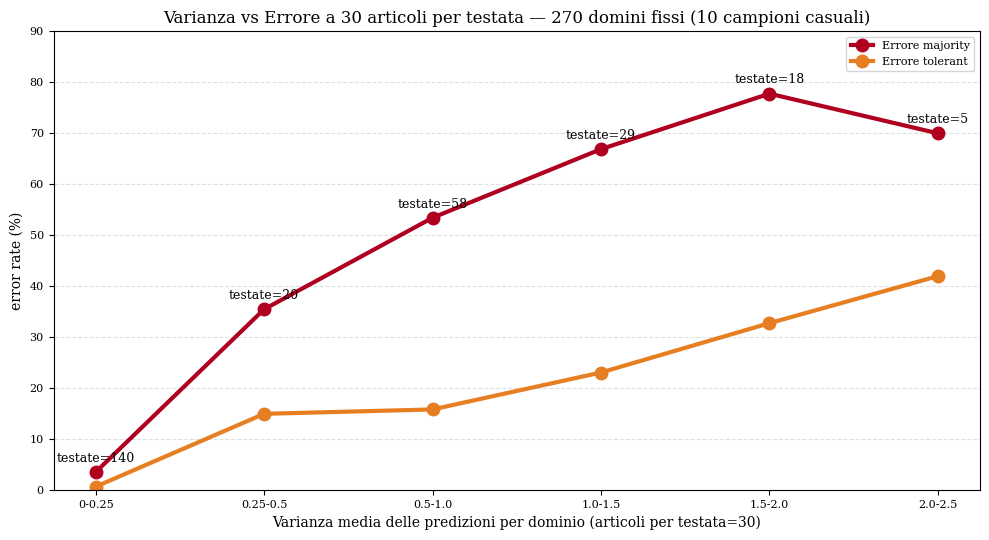

RISULTATI PER k=30
     bin   n  var_mean   err_maj   err_tol
  0-0.25 140  0.026344  3.571429  0.714286
0.25-0.5  20  0.370750 35.500000 15.000000
 0.5-1.0  58  0.789640 53.448276 15.862069
 1.0-1.5  29  1.188410 66.896552 23.103448
 1.5-2.0  18  1.679660 77.777778 32.777778
 2.0-2.5   5  2.172422 70.000000 42.000000



In [19]:
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

# --- DOMINI FISSI (≥30 articoli) ---
domini_fissi = bert.groupby('domain').filter(lambda g: len(g) >= 30)['domain'].unique()
bert_fisso = bert[bert['domain'].isin(domini_fissi)].copy()
print(f"Domini fissi: {len(domini_fissi)}")

bins = [0, 0.25, 0.5, 1.0, 1.5, 2.0, 2.5, 10]
labels = ['0-0.25','0.25-0.5','0.5-1.0','1.0-1.5','1.5-2.0','2.0-2.5','>2.5']

for k in [3, 6, 10, 30]:
    np.random.seed(42)
    rows = []

    for dom, g in bert_fisso.groupby('domain'):
        preds_all = g['y_pred'].values
        true = g['y_true'].mode()[0]

        vars_k = []
        maj_oks = []
        tol_oks = []

        for _ in range(10):
            sample = np.random.choice(preds_all, k, replace=False)
            var_k = np.var(sample)
            maj = Counter(sample).most_common(1)[0][0]

            vars_k.append(var_k)
            maj_oks.append(maj == true)
            tol_oks.append(abs(maj - true) <= 1)

        rows.append({
            'domain': dom,
            'var': np.mean(vars_k),
            'majority_ok': np.mean(maj_oks),
            'tolerant_ok': np.mean(tol_oks)
        })

    df = pd.DataFrame(rows)
    df['bin'] = pd.cut(df['var'], bins=bins, labels=labels, right=False)

    g = df.groupby('bin', observed=True).agg(
        err_maj=('majority_ok', lambda x: (1-x.mean())*100),
        err_tol=('tolerant_ok', lambda x: (1-x.mean())*100),
        n=('domain','count'),
        var_mean=('var','mean')
    ).reset_index()

    # --- PLOT ---
    plt.figure(figsize=(10,5.5))
    plt.plot(g['bin'], g['err_maj'], 'o-', lw=3, ms=9, color='#B00020', label='Errore majority')
    plt.plot(g['bin'], g['err_tol'], 'o-', lw=3, ms=9, color='#E67E22', label='Errore tolerant')

    for i, row in g.iterrows():
        if pd.notna(row['n']):
            plt.text(i, row['err_maj']+2, f"testate={int(row['n'])}", ha='center', fontsize=9)

    plt.ylabel('error rate (%)')
    plt.xlabel(f'Varianza media delle predizioni per dominio (articoli per testata={k})')
    plt.ylim(0, 90)
    plt.grid(axis='y', ls='--', alpha=0.4)
    plt.legend()
    plt.title(f'Varianza vs Errore a {k} articoli per testata — 270 domini fissi (10 campioni casuali)')
    plt.tight_layout()
    plt.savefig(f'varianza_errore_k{k}.png', dpi=300)
    plt.show()

    # --- STAMPA TABELLA ---
    print("="*60)
    print(f"RISULTATI PER k={k}")
    print("="*60)
    print(g[['bin','n','var_mean','err_maj','err_tol']].to_string(index=False))
    print()

Domini fissi: 270


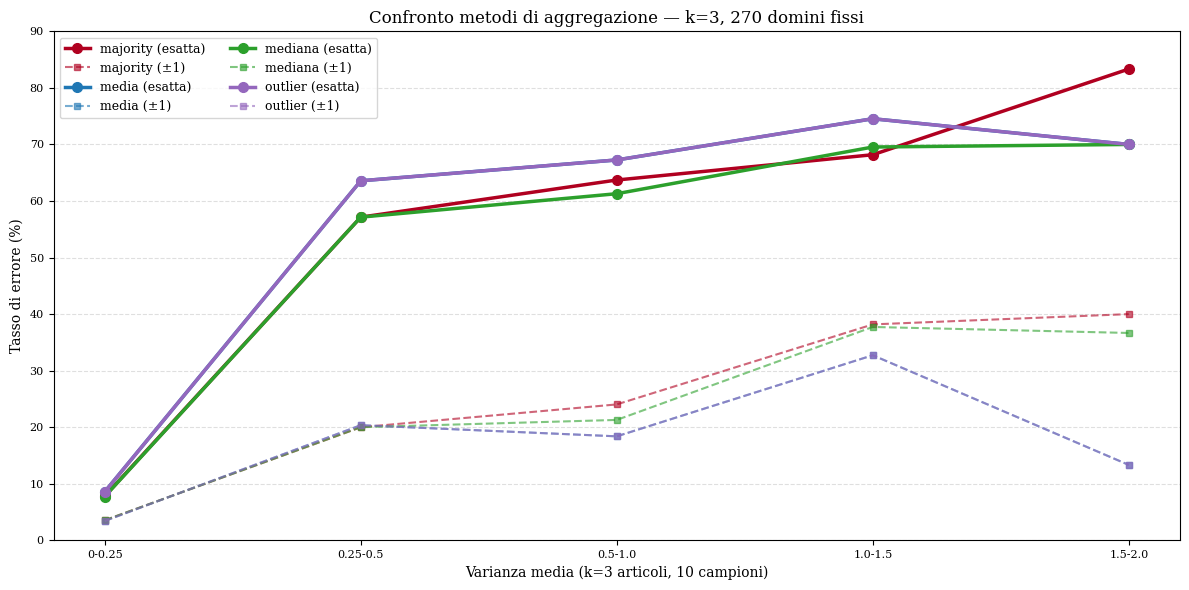

RISULTATI PER k=3 (trim=15%)
     bin   n  var_mean  err_majority  err_media  err_mediana  err_outlier
  0-0.25 155       0.0           7.8        8.6          7.7          8.6
0.25-0.5  28       0.4          57.1       63.6         57.1         63.6
 0.5-1.0  62       0.7          63.7       67.3         61.3         67.3
 1.0-1.5  22       1.2          68.2       74.5         69.5         74.5
 1.5-2.0   3       1.6          83.3       70.0         70.0         70.0



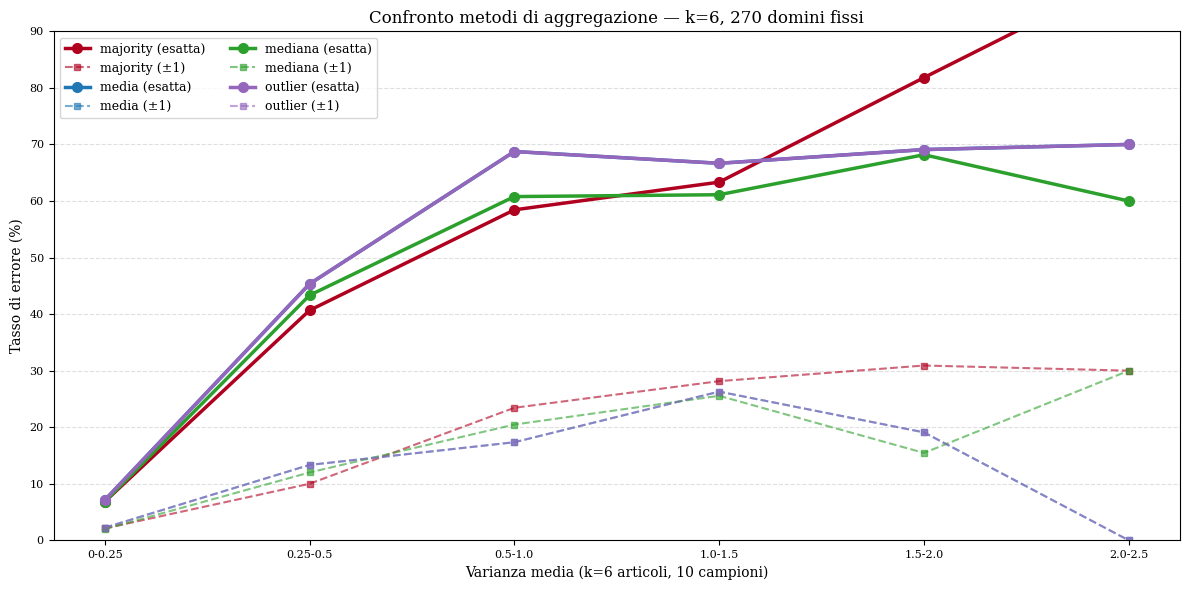

RISULTATI PER k=6 (trim=15%)
     bin   n  var_mean  err_majority  err_media  err_mediana  err_outlier
  0-0.25 152       0.0           6.8        7.1          6.8          7.1
0.25-0.5  15       0.4          40.7       45.3         43.3         45.3
 0.5-1.0  64       0.8          58.4       68.8         60.8         68.8
 1.0-1.5  27       1.2          63.3       66.7         61.1         66.7
 1.5-2.0  11       1.7          81.8       69.1         68.2         69.1
 2.0-2.5   1       2.1         100.0       70.0         60.0         70.0



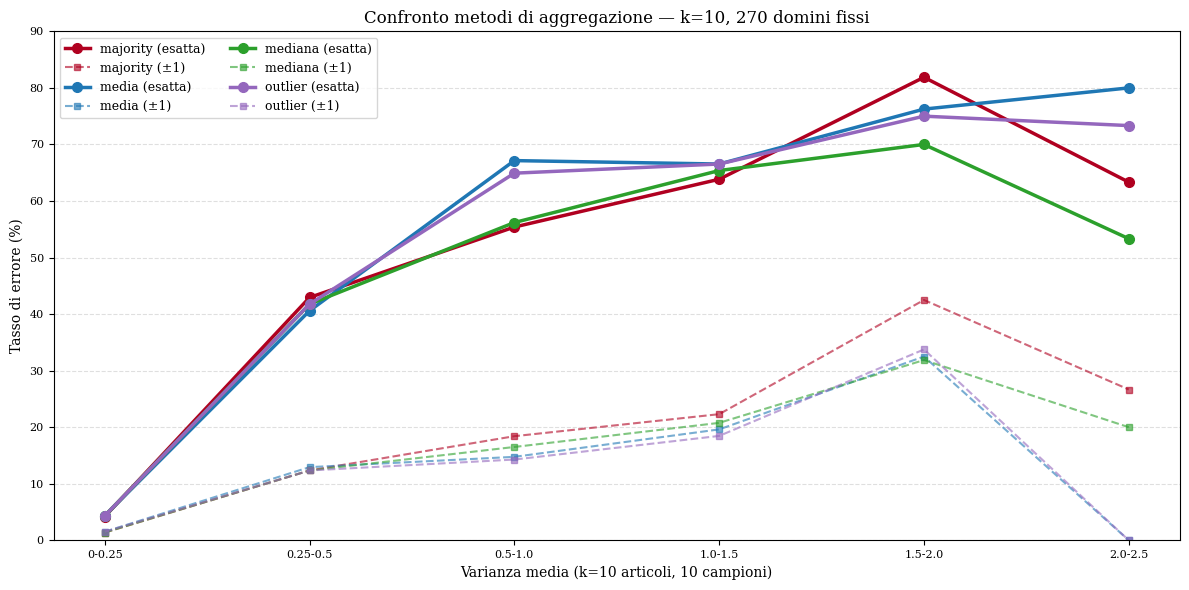

RISULTATI PER k=10 (trim=15%)
     bin   n  var_mean  err_majority  err_media  err_mediana  err_outlier
  0-0.25 145       0.0           4.2        4.3          4.3          4.3
0.25-0.5  17       0.4          42.9       40.6         41.8         41.8
 0.5-1.0  63       0.8          55.4       67.1         56.2         64.9
 1.0-1.5  26       1.2          63.8       66.5         65.4         66.5
 1.5-2.0  16       1.6          81.9       76.2         70.0         75.0
 2.0-2.5   3       2.1          63.3       80.0         53.3         73.3



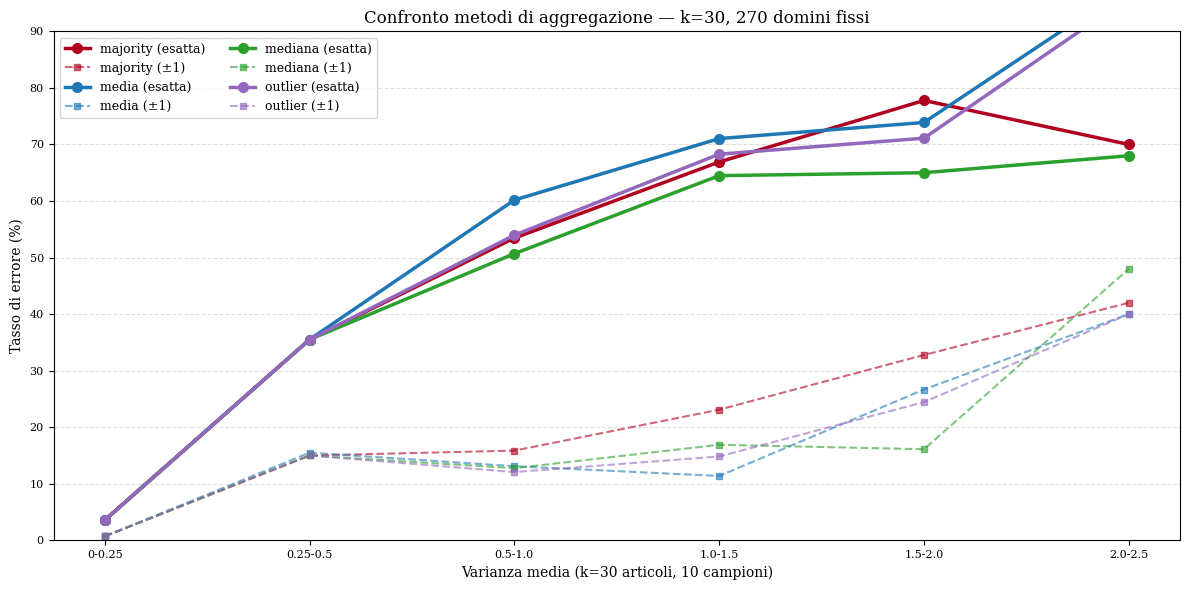

RISULTATI PER k=30 (trim=15%)
     bin   n  var_mean  err_majority  err_media  err_mediana  err_outlier
  0-0.25 140       0.0           3.6        3.6          3.6          3.6
0.25-0.5  20       0.4          35.5       35.5         35.5         35.5
 0.5-1.0  58       0.8          53.4       60.2         50.7         54.0
 1.0-1.5  29       1.2          66.9       71.0         64.5         68.3
 1.5-2.0  18       1.7          77.8       73.9         65.0         71.1
 2.0-2.5   5       2.2          70.0       98.0         68.0         96.0



In [23]:
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

# --- DOMINI FISSI (≥30 articoli) ---
domini_fissi = bert.groupby('domain').filter(lambda g: len(g) >= 30)['domain'].unique()
bert_fisso = bert[bert['domain'].isin(domini_fissi)].copy()
print(f"Domini fissi: {len(domini_fissi)}")

# --- PARAMETRO TRIM PROPORZIONALE ---
TRIM_RATIO = 0.15 # 15% da ogni lato

# --- METODI DI AGGREGAZIONE ---
def majority(x):
    return Counter(x).most_common(1)[0][0]

def media_arrotondata(x):
    return int(np.clip(round(np.mean(x)), 0, 4))

def mediana(x):
    return int(np.median(x))

def outlier_proporzionale(x): # <--- NUOVO
    x_sorted = np.sort(x)
    n = len(x_sorted)
    cut = int(n * TRIM_RATIO)
    if cut > 0 and n > 2*cut:
        x_trimmed = x_sorted[cut:-cut]
    else:
        x_trimmed = x_sorted # con k piccoli non taglia niente
    return int(np.clip(round(np.mean(x_trimmed)), 0, 4))

METODI = {
    'majority': majority,
    'media': media_arrotondata,
    'mediana': mediana,
    'outlier': outlier_proporzionale, # rinominato
}

COLORS = {'majority':'#B00020', 'media':'#1f77b4', 'mediana':'#2ca02c', 'outlier':'#9467bd'}

bins = [0, 0.25, 0.5, 1.0, 1.5, 2.0, 2.5, 10]
labels = ['0-0.25','0.25-0.5','0.5-1.0','1.0-1.5','1.5-2.0','2.0-2.5','>2.5']

for k in [3, 6, 10, 30]:
    np.random.seed(42)
    rows = []

    for dom, g in bert_fisso.groupby('domain'):
        preds_all = g['y_pred'].values
        true = g['y_true'].mode()[0]

        vars_k = []
        ok_maj = {m: [] for m in METODI}
        ok_tol = {m: [] for m in METODI}

        for _ in range(10):
            sample = np.random.choice(preds_all, k, replace=False)
            vars_k.append(np.var(sample))

            for nome, func in METODI.items():
                pred = func(sample)
                ok_maj[nome].append(pred == true)
                ok_tol[nome].append(abs(pred - true) <= 1)

        row = {'domain': dom, 'var': np.mean(vars_k)}
        for nome in METODI:
            row[f'{nome}_ok'] = np.mean(ok_maj[nome])
            row[f'{nome}_tol'] = np.mean(ok_tol[nome])
        rows.append(row)

    df = pd.DataFrame(rows)
    df['bin'] = pd.cut(df['var'], bins=bins, labels=labels, right=False)

    agg_dict = {'n': ('domain','count'), 'var_mean': ('var','mean')}
    for nome in METODI:
        agg_dict[f'err_{nome}'] = (f'{nome}_ok', lambda x: (1-x.mean())*100)
        agg_dict[f'err_{nome}_tol'] = (f'{nome}_tol', lambda x: (1-x.mean())*100)

    g = df.groupby('bin', observed=True).agg(**agg_dict).reset_index()

    # --- PLOT ---
    plt.figure(figsize=(12,6))
    for nome in METODI:
        plt.plot(g['bin'], g[f'err_{nome}'], 'o-', lw=2.5, ms=7,
                 color=COLORS[nome], label=f'{nome} (esatta)')
        plt.plot(g['bin'], g[f'err_{nome}_tol'], 's--', lw=1.5, ms=5,
                 color=COLORS[nome], alpha=0.6, label=f'{nome} (±1)')

    plt.ylabel('Tasso di errore (%)')
    plt.xlabel(f'Varianza media (k={k} articoli, 10 campioni)')
    plt.ylim(0, 90)
    plt.grid(axis='y', ls='--', alpha=0.4)
    plt.legend(ncol=2, fontsize=9)
    plt.title(f'Confronto metodi di aggregazione — k={k}, 270 domini fissi')
    plt.tight_layout()
    plt.savefig(f'confronto_metodi_k{k}.png', dpi=300)
    plt.show()

    # --- STAMPA ---
    print("="*80)
    print(f"RISULTATI PER k={k} (trim={TRIM_RATIO*100:.0f}%)")
    print("="*80)
    cols = ['bin','n','var_mean'] + [f'err_{m}' for m in METODI]
    print(g[cols].to_string(index=False, float_format='%.1f'))
    print()

## Risposta Fabio Pinelli

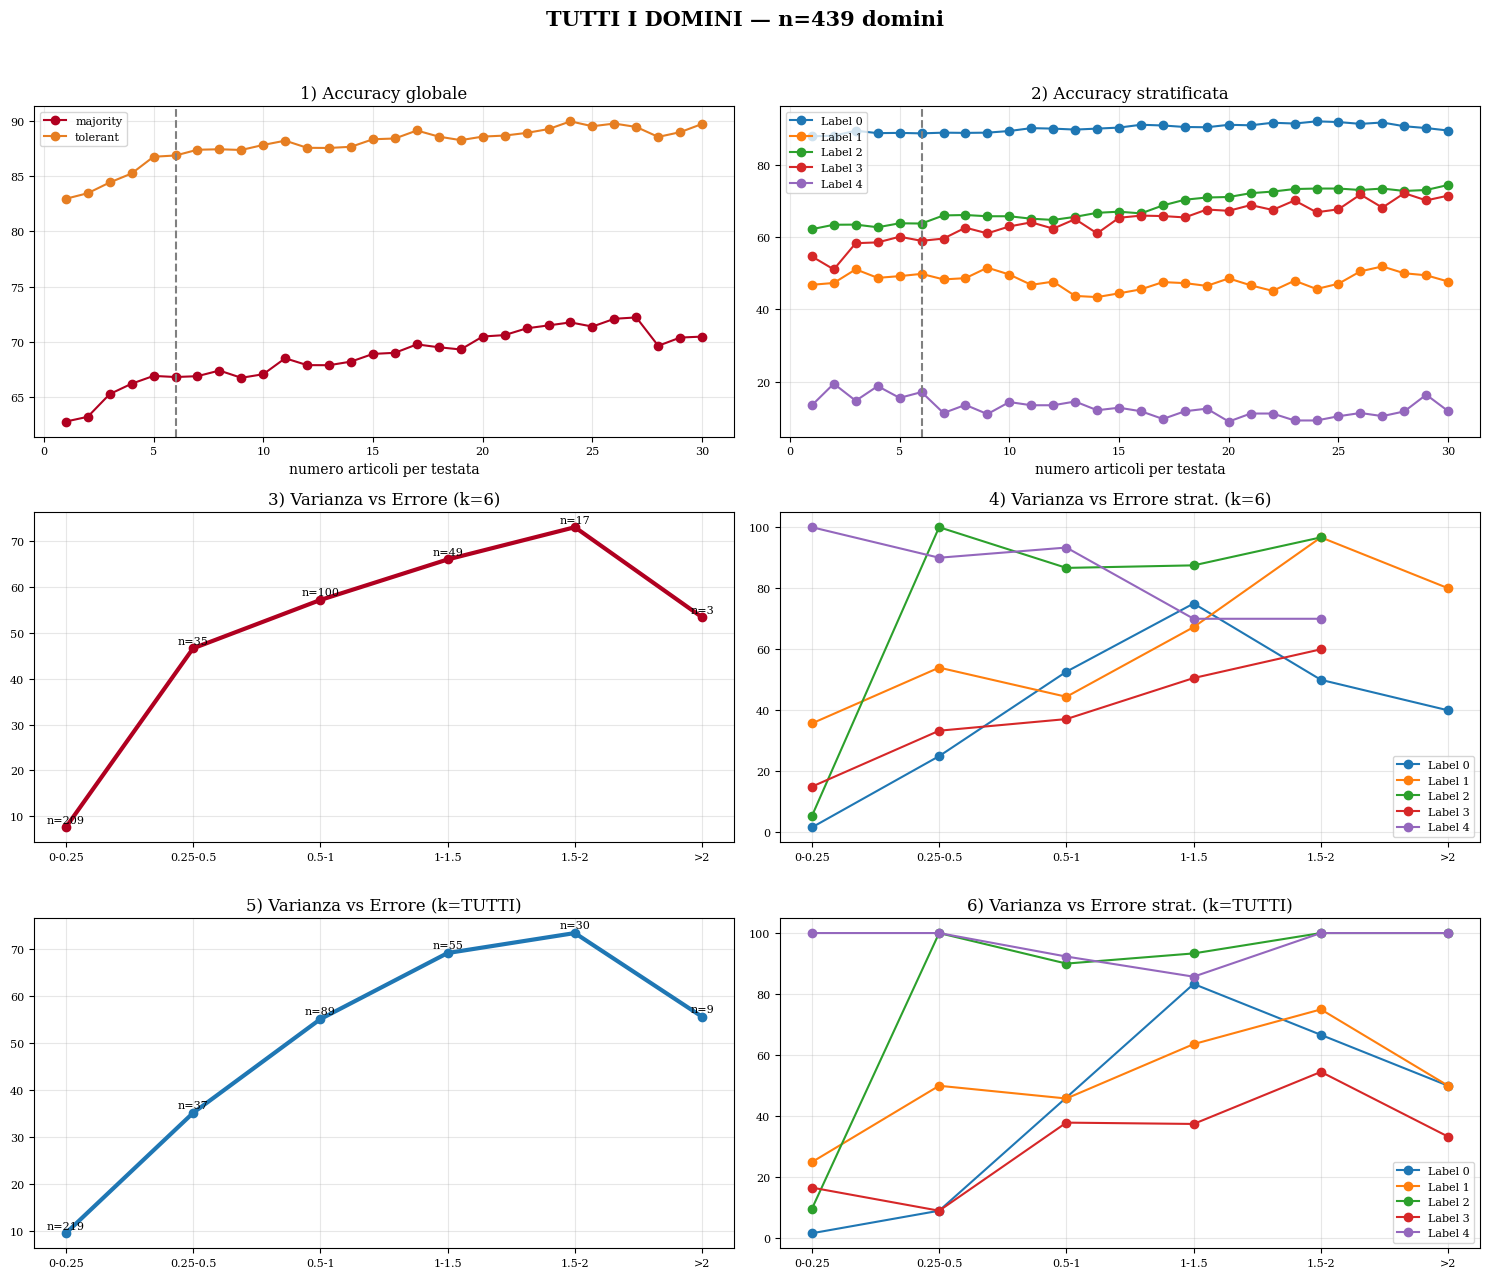

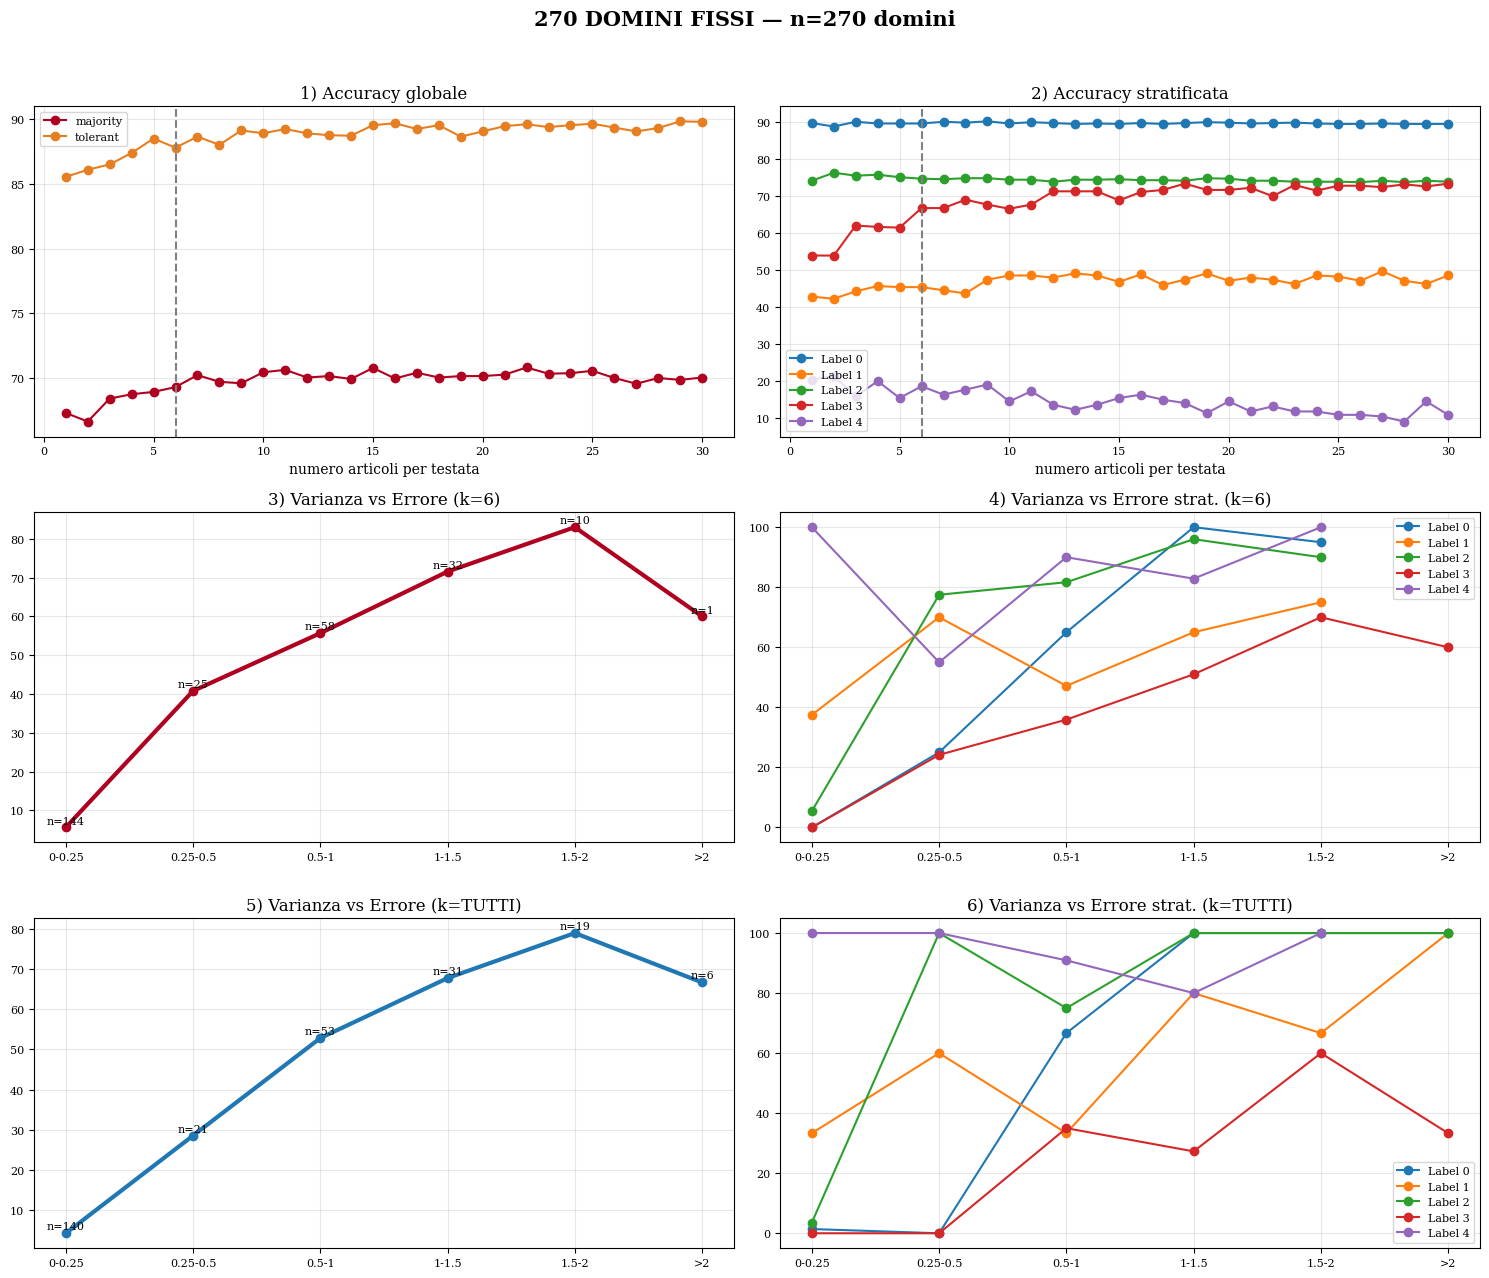

In [21]:
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

def analizza_completo(bert, min_articoli=None, titolo="TUTTI I DOMINI"):
    # --- setup ---
    if min_articoli:
        domini = bert.groupby('domain').filter(lambda x: len(x) >= min_articoli)['domain'].unique()
        bf = bert[bert['domain'].isin(domini)].copy()
    else:
        bf = bert.copy()
        domini = bf['domain'].unique()

    # FIX: prendi la label vera con first() (ogni dominio ha y_true costante)
    label_map = bf.groupby('domain')['y_true'].first().astype(int)
    bf['label'] = bf['domain'].map(label_map).astype(int)
    bf['y_pred'] = bf['y_pred'].astype(int) # assicura int vs int

    def majority(v): return Counter(v).most_common(1)[0][0]
    np.random.seed(42)
    k_max, n_rep, k_var = 30, 10, 6

    # --- 1) ACCURACY GLOBALE ---
    res_glob=[]
    for k in range(1,k_max+1):
        acc_m=acc_t=0; cnt=0
        for _,g in bf.groupby('domain'):
            if len(g)<k: continue
            true=int(g['y_true'].iloc[0]); preds=g['y_pred'].values; cnt+=1
            hm=ht=0
            for _ in range(n_rep):
                p=int(majority(np.random.choice(preds,k,replace=False)))
                hm+=(p==true); ht+=(abs(p-true)<=1)
            acc_m+=hm/n_rep; acc_t+=ht/n_rep
        res_glob.append([k,cnt,acc_m/cnt,acc_t/cnt])
    df_g=pd.DataFrame(res_glob,columns=['k','domini','maj','tol'])

    # --- 2) ACCURACY STRATIFICATA (FIX QUI) ---
    strat={}
    for lab in sorted(bf['label'].unique()):
        sub=bf[bf['label']==lab]; r=[]
        for k in range(1,k_max+1):
            acc_m=acc_t=0; cnt=0
            for _,g in sub.groupby('domain'):
                if len(g)<k: continue
                cnt+=1; preds=g['y_pred'].values
                hm=ht=0
                for _ in range(n_rep):
                    p=int(majority(np.random.choice(preds,k,replace=False)))
                    hm+=(p==lab); ht+=(abs(p-lab)<=1)
                acc_m+=hm/n_rep; acc_t+=ht/n_rep
            r.append([k, acc_m/cnt if cnt else np.nan, acc_t/cnt if cnt else np.nan])
        strat[lab]=pd.DataFrame(r,columns=['k','maj','tol'])

    # --- 3-6) VARIANZA ---
    def var_df(data, k_mode):
        rows=[]
        for dom,g in data.groupby('domain'):
            preds=g['y_pred'].values; true=int(g['y_true'].iloc[0]); lab=int(g['label'].iloc[0])
            if k_mode=='all':
                rows.append({'dom':dom,'var':np.var(preds),'ok':majority(preds)==true,'lab':lab})
            else:
                if len(preds)<k_mode: continue
                vs=[]; oks=[]
                for _ in range(n_rep):
                    s=np.random.choice(preds,k_mode,replace=False)
                    vs.append(np.var(s)); oks.append(majority(s)==true)
                rows.append({'dom':dom,'var':np.mean(vs),'ok':np.mean(oks),'lab':lab})
        return pd.DataFrame(rows)

    dv6 = var_df(bf, k_var); dv_all = var_df(bf, 'all')
    bins=[0,0.25,0.5,1,1.5,2,10]; labs=['0-0.25','0.25-0.5','0.5-1','1-1.5','1.5-2','>2']
    for df in [dv6,dv_all]: df['bin']=pd.cut(df['var'],bins=bins,labels=labs,right=False)

    # --- PLOT 3x2 ---
    fig, axs = plt.subplots(3,2, figsize=(15,13))
    fig.suptitle(f'{titolo} — n={len(domini)} domini', fontsize=15, weight='bold')

    axs[0,0].plot(df_g['k'], df_g['maj']*100, 'o-', color='#B00020', label='majority')
    axs[0,0].plot(df_g['k'], df_g['tol']*100, 'o-', color='#E67E22', label='tolerant')
    axs[0,0].axvline(6, ls='--', color='gray'); axs[0,0].set_title('1) Accuracy globale'); axs[0,0].set_xlabel('numero articoli per testata'); axs[0,0].legend(); axs[0,0].grid(alpha=0.3)

    for lab,df in strat.items(): axs[0,1].plot(df['k'], df['maj']*100, 'o-', label=f'Label {int(lab)}')
    axs[0,1].axvline(6, ls='--', color='gray'); axs[0,1].set_title('2) Accuracy stratificata'); axs[0,1].set_xlabel('numero articoli per testata'); axs[0,1].legend(); axs[0,1].grid(alpha=0.3)

    g6 = dv6.groupby('bin',observed=True).agg(err=('ok',lambda x:(1-x.mean())*100), n=('dom','count')).reset_index()
    axs[1,0].plot(g6['bin'], g6['err'], 'o-', lw=3, color='#B00020')
    for i,r in g6.iterrows(): axs[1,0].text(i,r['err']+1,f"n={int(r['n'])}",ha='center',fontsize=8)
    axs[1,0].set_title('3) Varianza vs Errore (k=6)'); axs[1,0].grid(alpha=0.3)

    for lab in sorted(dv6['lab'].unique()):
        sub=dv6[dv6['lab']==lab].groupby('bin',observed=True).agg(err=('ok',lambda x:(1-x.mean())*100)).reset_index()
        axs[1,1].plot(sub['bin'], sub['err'], 'o-', label=f'Label {int(lab)}')
    axs[1,1].set_title('4) Varianza vs Errore strat. (k=6)'); axs[1,1].legend(); axs[1,1].grid(alpha=0.3)

    gA = dv_all.groupby('bin',observed=True).agg(err=('ok',lambda x:(1-x.mean())*100), n=('dom','count')).reset_index()
    axs[2,0].plot(gA['bin'], gA['err'], 'o-', lw=3, color='#1f77b4')
    for i,r in gA.iterrows(): axs[2,0].text(i,r['err']+1,f"n={int(r['n'])}",ha='center',fontsize=8)
    axs[2,0].set_title('5) Varianza vs Errore (k=TUTTI)'); axs[2,0].grid(alpha=0.3)

    for lab in sorted(dv_all['lab'].unique()):
        sub=dv_all[dv_all['lab']==lab].groupby('bin',observed=True).agg(err=('ok',lambda x:(1-x.mean())*100)).reset_index()
        axs[2,1].plot(sub['bin'], sub['err'], 'o-', label=f'Label {int(lab)}')
    axs[2,1].set_title('6) Varianza vs Errore strat. (k=TUTTI)'); axs[2,1].legend(); axs[2,1].grid(alpha=0.3)

    plt.tight_layout(rect=[0,0,1,0.96]); plt.show()

# ESEGUI
analizza_completo(bert, min_articoli=None, titolo="TUTTI I DOMINI")
analizza_completo(bert, min_articoli=30, titolo="270 DOMINI FISSI")

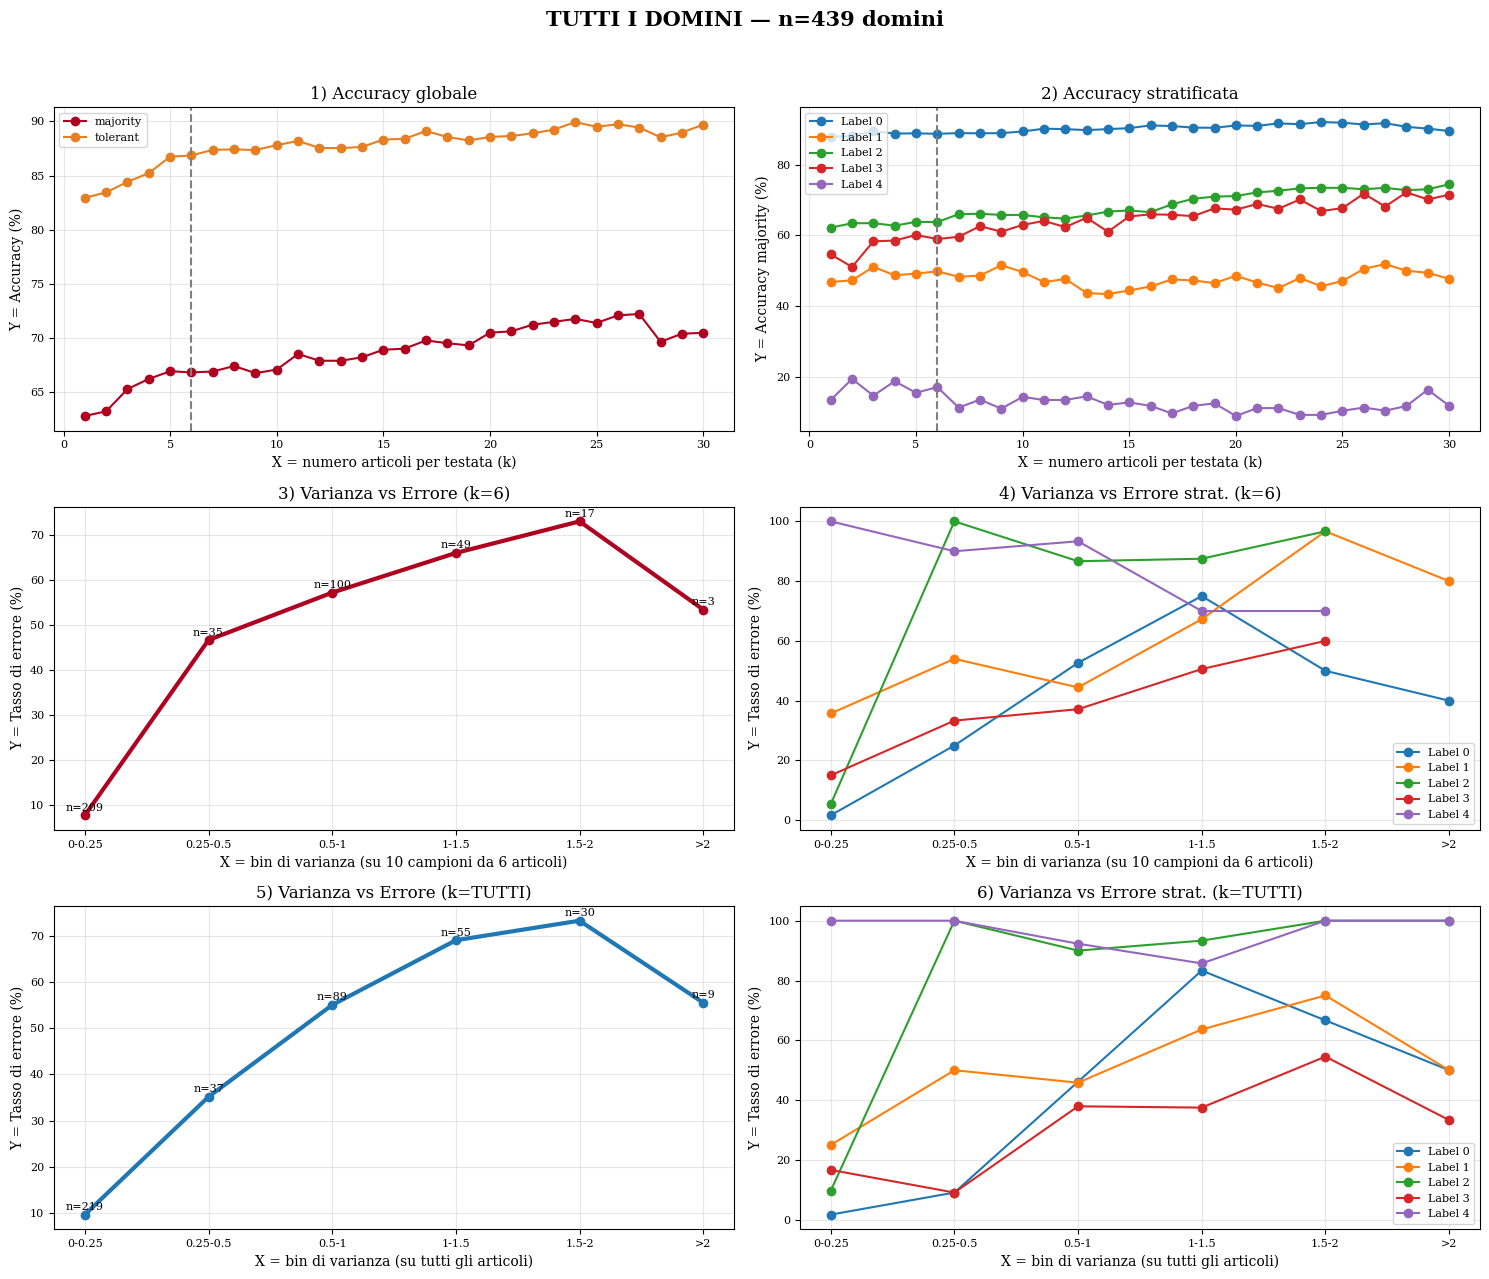

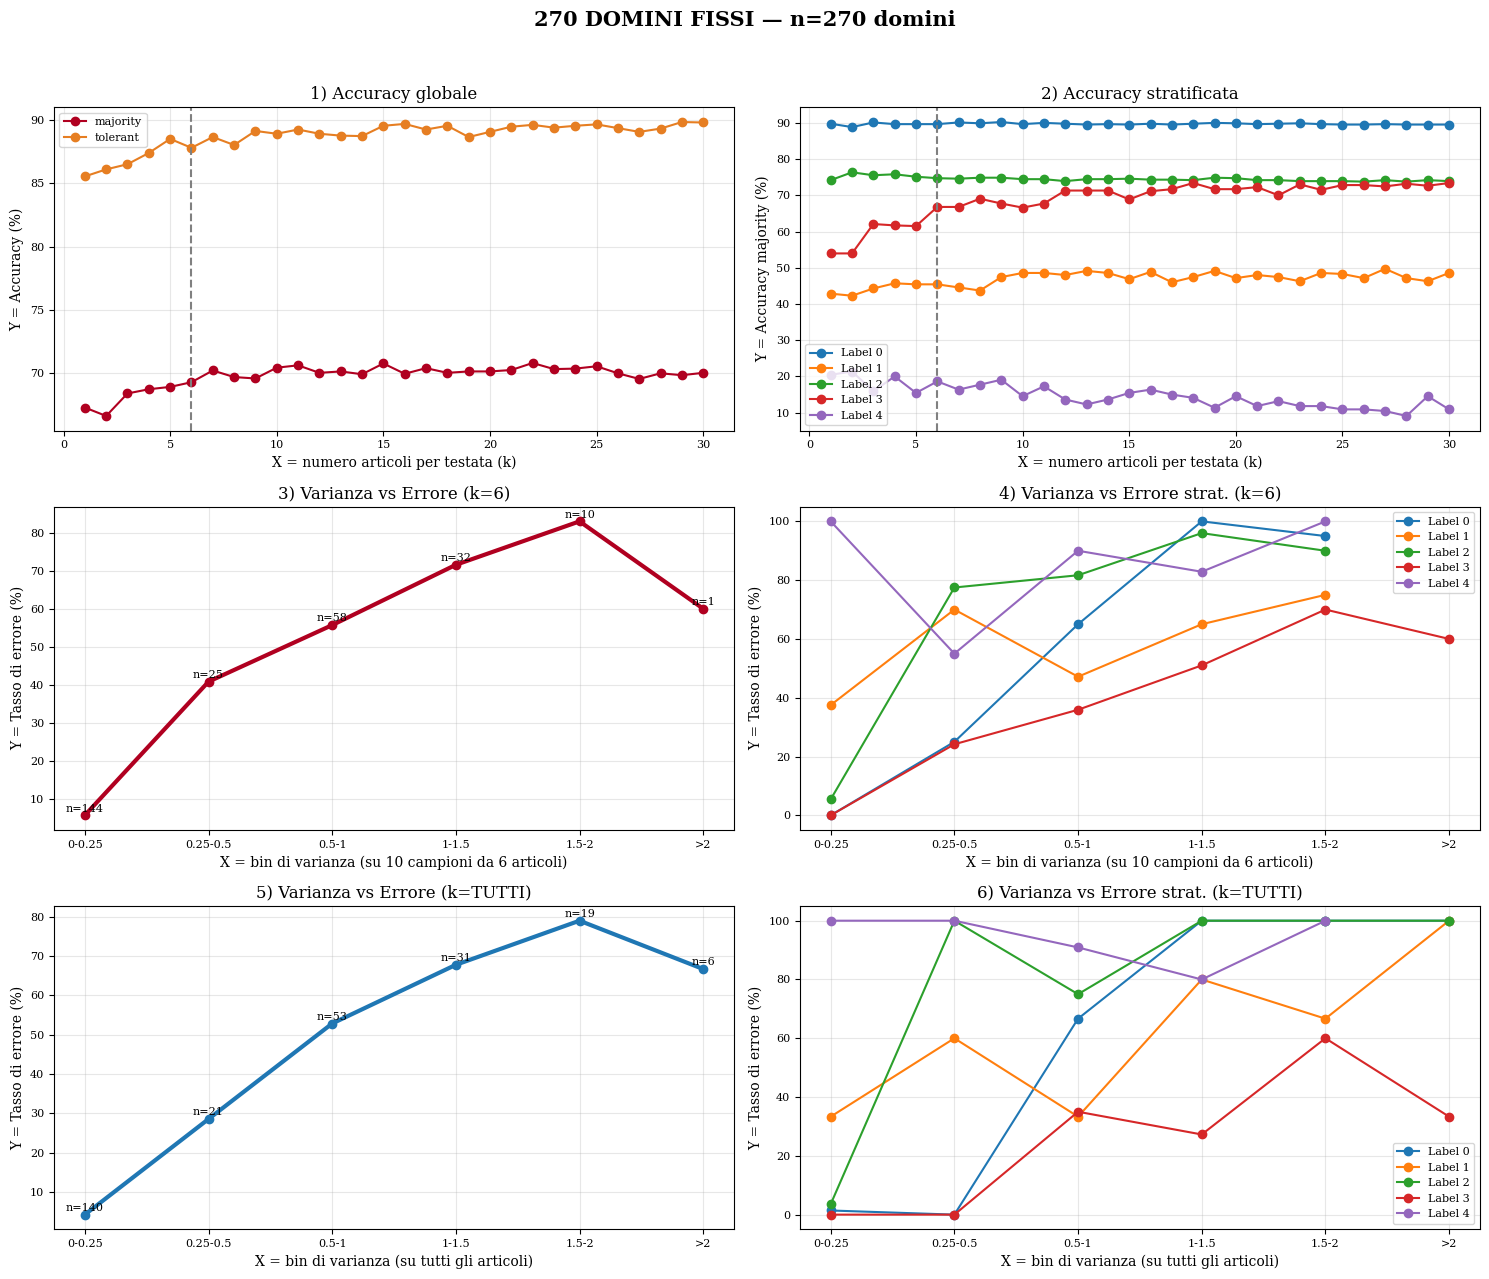

In [22]:
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

def analizza_completo(bert, min_articoli=None, titolo="TUTTI I DOMINI"):
    # --- setup ---
    if min_articoli:
        domini = bert.groupby('domain').filter(lambda x: len(x) >= min_articoli)['domain'].unique()
        bf = bert[bert['domain'].isin(domini)].copy()
    else:
        bf = bert.copy()
        domini = bf['domain'].unique()

    label_map = bf.groupby('domain')['y_true'].first().astype(int)
    bf['label'] = bf['domain'].map(label_map).astype(int)
    bf['y_pred'] = bf['y_pred'].astype(int)

    def majority(v): return Counter(v).most_common(1)[0][0]
    np.random.seed(42)
    k_max, n_rep, k_var = 30, 10, 6

    # --- 1) ACCURACY GLOBALE ---
    res_glob=[]
    for k in range(1,k_max+1):
        acc_m=acc_t=0; cnt=0
        for _,g in bf.groupby('domain'):
            if len(g)<k: continue
            true=int(g['y_true'].iloc[0]); preds=g['y_pred'].values; cnt+=1
            hm=ht=0
            for _ in range(n_rep):
                p=int(majority(np.random.choice(preds,k,replace=False)))
                hm+=(p==true); ht+=(abs(p-true)<=1)
            acc_m+=hm/n_rep; acc_t+=ht/n_rep
        res_glob.append([k,cnt,acc_m/cnt,acc_t/cnt])
    df_g=pd.DataFrame(res_glob,columns=['k','domini','maj','tol'])

    # --- 2) ACCURACY STRATIFICATA ---
    strat={}
    for lab in sorted(bf['label'].unique()):
        sub=bf[bf['label']==lab]; r=[]
        for k in range(1,k_max+1):
            acc_m=acc_t=0; cnt=0
            for _,g in sub.groupby('domain'):
                if len(g)<k: continue
                cnt+=1; preds=g['y_pred'].values
                hm=ht=0
                for _ in range(n_rep):
                    p=int(majority(np.random.choice(preds,k,replace=False)))
                    hm+=(p==lab); ht+=(abs(p-lab)<=1)
                acc_m+=hm/n_rep; acc_t+=ht/n_rep
            r.append([k, acc_m/cnt if cnt else np.nan, acc_t/cnt if cnt else np.nan])
        strat[lab]=pd.DataFrame(r,columns=['k','maj','tol'])

    # --- 3-6) VARIANZA ---
    def var_df(data, k_mode):
        rows=[]
        for dom,g in data.groupby('domain'):
            preds=g['y_pred'].values; true=int(g['y_true'].iloc[0]); lab=int(g['label'].iloc[0])
            if k_mode=='all':
                rows.append({'dom':dom,'var':np.var(preds),'ok':majority(preds)==true,'lab':lab})
            else:
                if len(preds)<k_mode: continue
                vs=[]; oks=[]
                for _ in range(n_rep):
                    s=np.random.choice(preds,k_mode,replace=False)
                    vs.append(np.var(s)); oks.append(majority(s)==true)
                rows.append({'dom':dom,'var':np.mean(vs),'ok':np.mean(oks),'lab':lab})
        return pd.DataFrame(rows)

    dv6 = var_df(bf, k_var); dv_all = var_df(bf, 'all')
    bins=[0,0.25,0.5,1,1.5,2,10]; labs=['0-0.25','0.25-0.5','0.5-1','1-1.5','1.5-2','>2']
    for df in [dv6,dv_all]: df['bin']=pd.cut(df['var'],bins=bins,labels=labs,right=False)

    # --- PLOT 3x2 ---
    fig, axs = plt.subplots(3,2, figsize=(15,13))
    fig.suptitle(f'{titolo} — n={len(domini)} domini', fontsize=15, weight='bold')

    # 1) Accuracy globale
    axs[0,0].plot(df_g['k'], df_g['maj']*100, 'o-', color='#B00020', label='majority')
    axs[0,0].plot(df_g['k'], df_g['tol']*100, 'o-', color='#E67E22', label='tolerant')
    axs[0,0].axvline(6, ls='--', color='gray')
    axs[0,0].set_title('1) Accuracy globale')
    axs[0,0].set_xlabel('X = numero articoli per testata (k)')
    axs[0,0].set_ylabel('Y = Accuracy (%)')
    axs[0,0].legend(); axs[0,0].grid(alpha=0.3)

    # 2) Accuracy stratificata
    for lab,df in strat.items():
        axs[0,1].plot(df['k'], df['maj']*100, 'o-', label=f'Label {int(lab)}')
    axs[0,1].axvline(6, ls='--', color='gray')
    axs[0,1].set_title('2) Accuracy stratificata')
    axs[0,1].set_xlabel('X = numero articoli per testata (k)')
    axs[0,1].set_ylabel('Y = Accuracy majority (%)')
    axs[0,1].legend(); axs[0,1].grid(alpha=0.3)

    # 3) Varianza vs Errore (k=6)
    g6 = dv6.groupby('bin',observed=True).agg(err=('ok',lambda x:(1-x.mean())*100), n=('dom','count')).reset_index()
    axs[1,0].plot(g6['bin'], g6['err'], 'o-', lw=3, color='#B00020')
    for i,r in g6.iterrows(): axs[1,0].text(i,r['err']+1,f"n={int(r['n'])}",ha='center',fontsize=8)
    axs[1,0].set_title('3) Varianza vs Errore (k=6)')
    axs[1,0].set_xlabel('X = bin di varianza (su 10 campioni da 6 articoli)')
    axs[1,0].set_ylabel('Y = Tasso di errore (%)')
    axs[1,0].grid(alpha=0.3)

    # 4) Varianza vs Errore strat. (k=6)
    for lab in sorted(dv6['lab'].unique()):
        sub=dv6[dv6['lab']==lab].groupby('bin',observed=True).agg(err=('ok',lambda x:(1-x.mean())*100)).reset_index()
        axs[1,1].plot(sub['bin'], sub['err'], 'o-', label=f'Label {int(lab)}')
    axs[1,1].set_title('4) Varianza vs Errore strat. (k=6)')
    axs[1,1].set_xlabel('X = bin di varianza (su 10 campioni da 6 articoli)')
    axs[1,1].set_ylabel('Y = Tasso di errore (%)')
    axs[1,1].legend(); axs[1,1].grid(alpha=0.3)

    # 5) Varianza vs Errore (k=TUTTI)
    gA = dv_all.groupby('bin',observed=True).agg(err=('ok',lambda x:(1-x.mean())*100), n=('dom','count')).reset_index()
    axs[2,0].plot(gA['bin'], gA['err'], 'o-', lw=3, color='#1f77b4')
    for i,r in gA.iterrows(): axs[2,0].text(i,r['err']+1,f"n={int(r['n'])}",ha='center',fontsize=8)
    axs[2,0].set_title('5) Varianza vs Errore (k=TUTTI)')
    axs[2,0].set_xlabel('X = bin di varianza (su tutti gli articoli)')
    axs[2,0].set_ylabel('Y = Tasso di errore (%)')
    axs[2,0].grid(alpha=0.3)

    # 6) Varianza vs Errore strat. (k=TUTTI)
    for lab in sorted(dv_all['lab'].unique()):
        sub=dv_all[dv_all['lab']==lab].groupby('bin',observed=True).agg(err=('ok',lambda x:(1-x.mean())*100)).reset_index()
        axs[2,1].plot(sub['bin'], sub['err'], 'o-', label=f'Label {int(lab)}')
    axs[2,1].set_title('6) Varianza vs Errore strat. (k=TUTTI)')
    axs[2,1].set_xlabel('X = bin di varianza (su tutti gli articoli)')
    axs[2,1].set_ylabel('Y = Tasso di errore (%)')
    axs[2,1].legend(); axs[2,1].grid(alpha=0.3)

    plt.tight_layout(rect=[0,0,1,0.96]); plt.show()

# ESEGUI
analizza_completo(bert, min_articoli=None, titolo="TUTTI I DOMINI")
analizza_completo(bert, min_articoli=30, titolo="270 DOMINI FISSI")